# **HAI 21.03 zero-day detection — v1: TabPFN density teacher vs. GMM baseline**

This notebook is `WADi_A1_2017_full_pipeline_v1.ipynb` pointed at **HAI 21.03**, with no surrogate. It produces the TabPFN teacher scores and the GMM scores that `HAI_baselines_v1.ipynb` reads from `results/HAI_full_pipeline_v1/` (§4 of that notebook), so the TabPFN row, the TabPFN+TranAD fusion and every paired comparison are filled in there.

#### Why HAI
- **A different plant** (boiler, turbine, water treatment, hardware-in-the-loop simulator), so unlike WADI A1 vs. A2 it is independent evidence.
- **50 labelled attack events** (WADI: 14), so the event-bootstrap intervals, which are the ones used for conclusions, should be much tighter.

#### Differences from the WADI A1 pipeline
| item | WADI A1 pipeline | this notebook |
|---|---|---|
| Clean files | `wadi2017_*` | `hai21_*` from `HAI_EDA_and_cleaning.ipynb` |
| Normal data | one 14-day file | `train1`–`train3`: three separate 1 Hz recordings (one `block` each), 6 h warm-up dropped from each |
| TEST | one attack file (9–11 Oct) | `test1`–`test5`: five separate recordings (7–31 Jul 2020), scored every 10 s |
| Order in time | TEST after the normal data | **TEST is not later than the training files** (`test1`–`test3` overlap the period of `train1`, `test4`–`test5` precede `train2`). Only the normal data is split chronologically. |
| CAL | last 30%, minus the A2-removed spans | last 30% of the concatenated normal data (end of `train3`, Aug 2020) |
| Tag rules | exclude AIT analysers, one set point, exclude level switches | none of those types exist in HAI: no type exclusion, no set points. Tags constant in FIT are dropped; near-duplicates (|Spearman| ≥ 0.98) are removed |
| Onset window | 300 s | 60 s (HAI attacks last 17–422 s, median ≈ 150 s) |
| Surrogate | out of scope | out of scope (teacher vs. GMM only) |

**Cost.** TEST has about 40,000 scored rows and CAL about 25,000, so the TabPFN teacher takes roughly 3–5 h on the GB10 (≈ 0.24 s per row). Members are cached per view and seed, so an interrupted run resumes.

**Calibration.** CAL (Aug 2020) and TEST (July 2020) are different recordings of a plant that drifts between recordings. The realised test FPR at the CAL 1% threshold, the adaptive threshold and the daily false-alarm table (E6) show how much that matters.

#### Evaluation protocol (unchanged)
Chronological split of the normal data (6 h warm-up per file dropped → FIT 70% → 1 h gap → CAL), TEST = the five attack files. One threshold rule for all methods (CAL 1% quantile), static and adaptive. CAL and TEST are sampled every 10 s. Two views of uncertainty: row-block and event bootstrap (the event one is used for conclusions). Every table in §E/§F is rebuilt from saved files. Figures go to `output-figures/<name>_hai2103_v1.png` at 600 dpi.

In [1]:
# Uncomment if the environment is missing dependencies.
# %pip install -q "tabpfn>=9.2" "tabpfn-extensions[unsupervised]>=0.6" scikit-learn pandas pyarrow numpy scipy matplotlib seaborn torch python-dotenv

## **0. Setup, configuration and versioning**

In [2]:
import gc
import hashlib
import importlib.metadata as importlib_metadata
import json
import os
import platform
import random
import re
import time
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import torch
from scipy import stats
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
import tabpfn
from tabpfn import TabPFNClassifier, TabPFNRegressor
from tabpfn_extensions.unsupervised import TabPFNUnsupervisedModel
from dotenv import load_dotenv

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))
print("tabpfn", tabpfn.__version__, "| torch", torch.__version__)

load_dotenv("/home/jaume/_DEVELOPMENT/_projects/secrets.env")   # adjust the path to where the file is
assert os.environ.get("TABPFN_TOKEN"), "TABPFN_TOKEN not found in secrets.env"

Device: cuda (NVIDIA GB10)
tabpfn 9.2.0 | torch 2.12.0+cu130


### **0.1 Configuration**

| block | changes … | cached in |
|---|---|---|
| `TEACHER_CONFIG` | data, split, feature views, TabPFN settings | `teacher/<teacher_fp>/members/` (one file per view × seed) |
| `GMM_CONFIG`, `EVAL_CONFIG` | baseline and evaluation | run directory (minutes) |

`SMOKE_TEST = True` runs end to end with tiny sizes into a separate run directory. Its results are not meaningful.

In [3]:
RUN_ID = "HAI_full_pipeline_v1"
FIG_VERSION = "hai2103_v1"
FIG_DPI = 600
SMOKE_TEST = False

CLEAN_DIR = Path("scada-data/HAI-21.03/clean")   # from HAI_EDA_and_cleaning.ipynb
FILE_PREFIX = "hai21"
RESULTS_ROOT = Path("results")
FIG_DIR = Path("output-figures")
SWAT_REFERENCE_DIR = RESULTS_ROOT / "SWaT_A1A2-full-pipeline-v3"   # for the cross-dataset comparison (§F3)

TEACHER_CONFIG = {
    "dataset": "HAI 21.03: eight 1 Hz recordings (train1-3 normal, test1-5 attacks), labels from the official `attack` column",
    # Chronological split (Plan §1)
    "drop_warmup": True,                  # first 6 h of every training file (is_warmup)
    "fit_fraction": 0.70,
    "fit_cal_gap_rows": 3600,
    "post_attack_guard_steps": 30,
    "cal_stride": 10,
    "test_stride": 10,                    # must equal cal_stride (adaptive threshold)
    # Tags and feature views (Plan §3 + SWaT v3 learnings)
    "setpoint_tags": [],                  # HAI has no set points (every *_SP tag would go to the state view only)
    "exclude_types": [],                  # no analyser tags in HAI
    "max_mode_share": 0.99,               # drop sensors holding one value in >= 99% of FIT rows
    "actuator_exclude_types": [],         # constant discrete tags are dropped by the FIT rule
    "include_actuators": True,
    "dedup_spearman": 0.98,               # FIT-only redundancy rule
    "detrend_window_s": 600,
    "dynamics_window_s": 60,
    "views": ["state", "detrend", "dynamics"],
    # TabPFN density teacher (same settings as SWaT v3)
    "teacher_seeds": [42, 43, 44],
    "context_size": 5000,
    "n_estimators": 1,
    "n_permutations": 4,
    "score_batch_size": 4096,
}
GMM_CONFIG = {"components_grid": [4, 8, 16, 32, 48, 64, 96, 128], "covariance": "full", "reg_covar": 1e-4,
              "fit_stride": 20, "seed": 42}
EVAL_CONFIG = {
    "fusions": {"fused": ["state", "detrend", "dynamics"], "fused-sd": ["state", "dynamics"]},
    "primary": "fused",                   # same headline fusion as SWaT v3
    "target_fpr": 0.01,
    "fpr_grid": [0.005, 0.01, 0.02, 0.05],
    "bootstrap_block_rows": 360,          # 360 rows x 10 s = 1 h
    "bootstrap_repeats": 1000,
    "bootstrap_seed": 2026,
    "adaptive_window_s": 86400,
    "adaptive_gap_s": 3600,
    "adaptive_min_history_s": 7200,
    "pauc_max_fpr": 0.10,
    "onset_s": 60,                        # HAI attacks are short (17–422 s, median ≈ 150 s)
}
# Measured on SWaT v3 (GB10, 4 permutations): ≈ 0.65 ms per scored row, per feature, per seed.
TABPFN_MS_PER_ROW_FEATURE = 0.65

if SMOKE_TEST:
    RUN_ID += "-smoke"
    FIG_VERSION += "-smoke"
    TEACHER_CONFIG.update({"teacher_seeds": [42], "context_size": 500, "cal_stride": 120, "test_stride": 120,
                           "n_permutations": 1})
    GMM_CONFIG["components_grid"] = [4, 8]
    EVAL_CONFIG.update({"bootstrap_repeats": 50, "bootstrap_block_rows": 30,
                        "adaptive_window_s": 21600, "adaptive_min_history_s": 3600})


def fingerprint(obj):
    return hashlib.sha1(json.dumps(obj, sort_keys=True).encode()).hexdigest()[:10]


TEACHER_FINGERPRINT = fingerprint(TEACHER_CONFIG)
RUN_FINGERPRINT = fingerprint([TEACHER_CONFIG, GMM_CONFIG, EVAL_CONFIG])
RUN_DIR = RESULTS_ROOT / RUN_ID
TEACHER_DIR = RUN_DIR / "teacher" / TEACHER_FINGERPRINT
for d in [RUN_DIR, TEACHER_DIR / "members", FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)


def package_version(name):
    try:
        return importlib_metadata.version(name)
    except importlib_metadata.PackageNotFoundError:
        return "not installed"


ENVIRONMENT = {
    "python": platform.python_version(), "platform": platform.platform(), "device": DEVICE,
    "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None,
    "tabpfn": tabpfn.__version__, "tabpfn_extensions": package_version("tabpfn-extensions"),
    "torch": torch.__version__, "scikit-learn": package_version("scikit-learn"),
    "pandas": pd.__version__, "numpy": np.__version__,
}
config_path = RUN_DIR / "config.json"
teacher_config_path = TEACHER_DIR / "teacher_config.json"
previous_teacher = json.loads(teacher_config_path.read_text()) if teacher_config_path.exists() else {}
teacher_config_path.write_text(json.dumps({
    "teacher_config": TEACHER_CONFIG, "teacher_fingerprint": TEACHER_FINGERPRINT,
    "environment": previous_teacher.get("environment", ENVIRONMENT),
    "tabpfn_checkpoint": previous_teacher.get("tabpfn_checkpoint"),
    "created": previous_teacher.get("created", datetime.now().isoformat(timespec="seconds")),
}, indent=2))
config_path.write_text(json.dumps({
    "run_id": RUN_ID, "run_fingerprint": RUN_FINGERPRINT, "teacher_fingerprint": TEACHER_FINGERPRINT,
    "teacher_dir": TEACHER_DIR.as_posix(), "teacher_config": TEACHER_CONFIG, "gmm_config": GMM_CONFIG,
    "eval_config": EVAL_CONFIG, "figures": {"dir": FIG_DIR.as_posix(), "version": FIG_VERSION, "dpi": FIG_DPI},
    "environment": ENVIRONMENT, "written": datetime.now().isoformat(timespec="seconds"),
}, indent=2))

print(f"RUN_ID:              {RUN_ID}")
print(f"Run fingerprint:     {RUN_FINGERPRINT}")
print(f"Teacher fingerprint: {TEACHER_FINGERPRINT}  -> {TEACHER_DIR}")
print(f"Figures:             {FIG_DIR}/<name>_{FIG_VERSION}.png @ {FIG_DPI} dpi")

RUN_ID:              HAI_full_pipeline_v1
Run fingerprint:     7fbfd28556
Teacher fingerprint: 3998d76cb7  -> results/HAI_full_pipeline_v1/teacher/3998d76cb7
Figures:             output-figures/<name>_hai2103_v1.png @ 600 dpi


### **0.2 Shared helpers**

These are the same definitions as SWaT v3, plus `event_bootstrap_indices`, which resamples attacks and normal blocks separately. Every score follows the same convention: **higher = more anomalous**.

In [4]:
def save_fig(fig, name):
    path = FIG_DIR / f"{name}_{FIG_VERSION}.png"
    fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight")
    print(f"figure saved: {path}")


def post_attack_guard_mask(is_attack, guard_steps):
    # True = keep. Drops attack rows and the `guard_steps` rows right after each attack.
    is_attack = np.asarray(is_attack).astype(bool)
    keep = ~is_attack
    first_after_attack = np.flatnonzero(is_attack[:-1] & ~is_attack[1:]) + 1
    for start in first_after_attack:
        keep[start:start + guard_steps] = False
    return keep


def threshold_from_calibration(cal_scores, fpr):
    cal_scores = np.asarray(cal_scores)
    return float(np.quantile(cal_scores[np.isfinite(cal_scores)], 1.0 - fpr))


def point_metrics(y, scores, threshold):
    y = np.asarray(y).astype(bool)
    pred = np.asarray(scores) >= threshold
    tp = int((pred & y).sum()); fp = int((pred & ~y).sum())
    fn = int((~pred & y).sum()); tn = int((~pred & ~y).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return {
        "roc_auc": roc_auc_score(y, scores),
        "average_precision": average_precision_score(y, scores),
        "precision": precision,
        "recall": recall,
        "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        "test_fpr": fp / (fp + tn) if fp + tn else 0.0,
        "accuracy": (tp + tn) / len(y),
    }


def contiguous_runs(mask):
    # Half-open (start, stop) index pairs of consecutive True values.
    padded = np.concatenate([[0], np.asarray(mask, dtype=np.int8), [0]])
    edges = np.diff(padded)
    return list(zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)))


def event_metrics(timestamps, y, pred, segments):
    ts = pd.DatetimeIndex(timestamps)
    y = np.asarray(y).astype(bool)
    pred = np.asarray(pred).astype(bool)
    per_event = []
    for seg in segments.itertuples(index=False):
        lo = ts.searchsorted(seg.start, side="left")
        hi = ts.searchsorted(seg.end, side="right")
        hits = np.flatnonzero(pred[lo:hi])
        detected = hits.size > 0
        per_event.append({
            "segment": seg.segment,
            "attack_id": seg.attack_id,
            "attack_point": seg.attack_point,
            "start": seg.start,
            "duration_s": seg.duration_s,
            "test_rows": hi - lo,
            "detected": detected,
            "time_to_detect_s": (ts[lo + hits[0]] - seg.start).total_seconds() if detected else np.nan,
            "fraction_alarmed": float(pred[lo:hi].mean()) if hi > lo else np.nan,
        })
    per_event = pd.DataFrame(per_event)

    alarm_runs = contiguous_runs(pred)
    true_runs = sum(bool(y[a:b].any()) for a, b in alarm_runs)
    tp = int((pred & y).sum())
    point_precision = tp / pred.sum() if pred.sum() else 0.0
    event_recall = float(per_event["detected"].mean())
    summary = {
        "attacks_detected": int(per_event["detected"].sum()),
        "attacks_total": len(per_event),
        "event_recall": event_recall,
        "event_precision": true_runs / len(alarm_runs) if alarm_runs else 0.0,
        "alarm_runs": len(alarm_runs),
        "false_alarm_episodes": len(alarm_runs) - true_runs,
        "composite_f1": (2 * point_precision * event_recall / (point_precision + event_recall)
                         if point_precision + event_recall else 0.0),
        "median_ttd_s": float(per_event["time_to_detect_s"].median()),
    }
    return summary, per_event


def daily_false_alarm_rate(timestamps, y, pred):
    # Fraction of normal rows alarmed, per calendar day.
    normal = np.asarray(y) == 0
    days = pd.DatetimeIndex(timestamps).date
    return pd.Series(np.asarray(pred)[normal]).groupby(days[normal]).mean()


def adaptive_normalise(cal_scores, test_scores, stride_s, cfg):
    # Label-free online normalisation: (s_t - median) / IQR over the trailing window
    # [t - window, t - gap], counted in observed rows. CAL and TEST share the stride, so the
    # first TEST rows use the last CAL hours as their history (HAI: TEST starts in a different recording, so these first rows are a weak history).
    s = pd.Series(np.concatenate([cal_scores, test_scores]).astype(np.float64))
    window = int(cfg["adaptive_window_s"] / stride_s)
    gap = int(cfg["adaptive_gap_s"] / stride_s)
    min_rows = int(cfg["adaptive_min_history_s"] / stride_s)
    history = s.shift(gap).rolling(window, min_periods=min_rows)
    median = history.median()
    iqr = (history.quantile(0.75) - history.quantile(0.25)).where(lambda v: v > 0)
    z = ((s - median) / iqr).to_numpy()
    return z[:len(cal_scores)], z[len(cal_scores):]


def tpr_at_fpr(y, scores, fpr):
    f, t, _ = roc_curve(y, scores)
    return float(np.interp(fpr, f, t))


def block_bootstrap_indices(n, block, rng):
    # Circular block bootstrap: concatenate random wrap-around blocks of length `block`.
    starts = rng.integers(0, n, int(np.ceil(n / block)))
    return ((starts[:, None] + np.arange(block)[None, :]) % n).ravel()[:n]


def event_bootstrap_indices(attack_units, normal_units, rng):
    # Stratified event bootstrap: resample whole attacks and whole normal blocks, separately.
    pick_a = rng.integers(0, len(attack_units), len(attack_units))
    pick_n = rng.integers(0, len(normal_units), len(normal_units))
    return np.concatenate([attack_units[i] for i in pick_a] + [normal_units[i] for i in pick_n])


def robust_z(values, reference):
    median = np.median(reference)
    iqr = np.subtract(*np.percentile(reference, [75, 25]))
    return (values - median) / (iqr if iqr > 0 else 1.0)


def shade_attacks(ax, segments, color="#e76f51", alpha=0.25):
    for seg in segments.itertuples(index=False):
        ax.axvspan(seg.start, seg.end, color=color, alpha=alpha, lw=0)

## **1. Load the clean HAI files**

The files come from `HAI_EDA_and_cleaning.ipynb` (cleaning v2):
- **Normal** = `train1`–`train3` (`block_id` 0–2); **attack** = `test1`–`test5` (`block_id` 3–7). Every file is exactly 1 Hz with no gaps inside.
- **Labels.** `is_attack` is the official `attack` column; events are its runs per test file (50). `attack_point` names the attacked process (P1/P2/P3).
- **`is_warmup`** flags the first 6 h of every training file.

The stream is the normal files followed by the attack files. The `block` id changes at every file boundary (gap or time reversal), so no rolling window crosses a file.

In [5]:
%%time
metadata = json.loads((CLEAN_DIR / f"{FILE_PREFIX}_metadata.json").read_text())
assert metadata.get("cleaning_version", 1) >= 2, "Re-run the cleaning notebook: the v2 file format is required."
normal_df = pd.read_csv(CLEAN_DIR / f"{FILE_PREFIX}_normal_clean.csv", parse_dates=["timestamp"])
attack_df = pd.read_csv(CLEAN_DIR / f"{FILE_PREFIX}_attack_clean.csv", parse_dates=["timestamp"], dtype={"attack_id": "string"})
segments = pd.read_csv(CLEAN_DIR / f"{FILE_PREFIX}_label_segments.csv", parse_dates=["start", "end"], dtype={"attack_id": str})
segments = segments[["segment", "start", "end", "duration_s", "attack_id", "attack_point"]]

for df in (normal_df, attack_df):
    assert df.groupby("block_id")["timestamp"].apply(lambda t: t.is_monotonic_increasing).all()
assert normal_df["is_attack"].sum() == 0, "The normal files must be attack-free"
SENSORS_ALL = [s for s in metadata["sensors"] if s in normal_df.columns]
ACTUATORS_ALL = [a for a in metadata["actuators"] if a in normal_df.columns]
tags = SENSORS_ALL + ACTUATORS_ALL
missing_cells = {"normal": int(normal_df[tags].isna().sum().sum()), "attack": int(attack_df[tags].isna().sum().sum())}
normal_df[tags] = normal_df.groupby("block_id")[tags].transform(lambda s: s.ffill().bfill())
attack_df[tags] = attack_df.groupby("block_id")[tags].transform(lambda s: s.ffill().bfill())
print(f"Cells still missing after the cleaner's {metadata['ffill_limit_s']} s forward-fill (now filled): {missing_cells}")

display(segments.head(10))
print(f"Labelled segments: {len(segments)}")

stream = pd.concat([normal_df.assign(source="normal"), attack_df.assign(source="attack")], ignore_index=True)
stream["is_warmup"] = stream["is_warmup"].fillna(0).astype(bool)
gaps = stream["timestamp"].diff().dt.total_seconds().fillna(1.0)
stream["block"] = (gaps != 1.0).cumsum()          # one block per file (gaps and time reversals), no window crosses a file boundary
display(stream.groupby("block").agg(source=("source", "first"), start=("timestamp", "min"),
                                    end=("timestamp", "max"), rows=("timestamp", "size")))
print(f"Tags: {len(SENSORS_ALL)} sensors + {len(ACTUATORS_ALL)} discrete")

Cells still missing after the cleaner's 5 s forward-fill (now filled): {'normal': 0, 'attack': 0}


,segment,start,end,duration_s,attack_id,attack_point
0,1,2020-07-07 15:35:11,2020-07-07 15:38:22,192.0,1,P1
1,2,2020-07-07 17:28:11,2020-07-07 17:29:48,98.0,2,P1
2,3,2020-07-07 18:59:11,2020-07-07 19:02:20,190.0,3,P1
3,4,2020-07-07 20:21:06,2020-07-07 20:22:05,60.0,4,P2
4,5,2020-07-07 21:03:21,2020-07-07 21:04:49,89.0,5,P2
5,6,2020-07-09 15:47:00,2020-07-09 15:48:22,83.0,6,P2
6,7,2020-07-09 17:38:00,2020-07-09 17:45:01,422.0,7,P1
7,8,2020-07-09 18:59:06,2020-07-09 18:59:22,17.0,8,P1
8,9,2020-07-09 20:10:00,2020-07-09 20:14:18,259.0,9,P1
9,10,2020-07-09 21:15:00,2020-07-09 21:17:02,123.0,10,P1


Labelled segments: 50


,source,start,end,rows
block,,,,
0,normal,2020-07-11 00:00:00,2020-07-13 12:00:00,216001
1,normal,2020-07-31 22:00:00,2020-08-03 13:00:00,226801
2,normal,2020-08-04 22:00:00,2020-08-10 11:00:00,478801
3,attack,2020-07-07 15:00:00,2020-07-08 03:00:00,43201
4,attack,2020-07-09 15:00:00,2020-07-11 00:00:00,118801
5,attack,2020-07-13 00:00:00,2020-07-14 06:00:00,108001
6,attack,2020-07-28 12:00:00,2020-07-28 23:00:00,39601
7,attack,2020-07-30 10:50:00,2020-07-31 12:30:00,92401


Tags: 56 sensors + 23 discrete
CPU times: user 3.39 s, sys: 411 ms, total: 3.8 s
Wall time: 3.8 s


## **2. Chronological split of the normal data**

```
 normal data: train1 | train2 | train3 (concatenated, 6 h warm-up dropped from each file)
 |------------------ FIT (70%) ------------------|gap 1h|------- CAL (last 30%, end of train3) -------|
   TabPFN contexts, GMM fit, scalers                                   threshold, score calibration

 TEST = test1 … test5 (five separate recordings, 7–31 Jul 2020; NOT later in time than the normal data), every 10 s
```

In [6]:
assert TEACHER_CONFIG["cal_stride"] == TEACHER_CONFIG["test_stride"], "adaptive threshold needs equal CAL/TEST strides"
normal_mask = (stream["source"] == "normal").to_numpy(copy=True)
if TEACHER_CONFIG["drop_warmup"]:
    normal_mask &= ~stream["is_warmup"].to_numpy()
normal_pos = np.flatnonzero(normal_mask)
fit_end = int(TEACHER_CONFIG["fit_fraction"] * len(normal_pos))
fit_pos = normal_pos[:fit_end]
cal_pos = normal_pos[fit_end + TEACHER_CONFIG["fit_cal_gap_rows"]:]
guard = TEACHER_CONFIG["post_attack_guard_steps"]
fit_keep = post_attack_guard_mask(stream["is_attack"].to_numpy()[fit_pos], guard)
cal_keep = post_attack_guard_mask(stream["is_attack"].to_numpy()[cal_pos], guard)
fit_pos = fit_pos[fit_keep]
cal_pos = cal_pos[cal_keep][::TEACHER_CONFIG["cal_stride"]]
test_pos = np.flatnonzero((stream["source"] == "attack").to_numpy())[::TEACHER_CONFIG["test_stride"]]
print(f"Post-attack guard rows removed: FIT {int((~fit_keep).sum())}, CAL {int((~cal_keep).sum())} (TEST: not applied)")
print(f"FIT {len(fit_pos):,} rows (1 Hz) | CAL {len(cal_pos):,} | TEST {len(test_pos):,} (every {TEACHER_CONFIG['test_stride']} s)")

Post-attack guard rows removed: FIT 0, CAL 0 (TEST: not applied)
FIT 599,762 rows (1 Hz) | CAL 25,345 | TEST 40,201 (every 10 s)


## **3. Tag selection and feature views**

All selection rules use **FIT only** and no labels:
1. **Set points / demand** (`*_SP`, `TOTAL_CONS_REQUIRED_FLOW`) go into the state view only.
2. **Continuous sensors** = the remaining sensors, without the analysers (AIT) and without sensors that hold one value in ≥ 99% of FIT rows. Near-duplicates (|Spearman| ≥ 0.98) are removed greedily, keeping the first in tag order.
3. **Actuators** = those that change during FIT, excluding level-switch alarms and AIT tags, de-duplicated with the same rule.

| View | Features | What it sees |
|---|---|---|
| **state** | continuous sensors + set points + actuators | *Where* the plant is (level-drift sensitive) |
| **detrend** | each continuous sensor − causal 600 s trailing mean | *What just changed* (onsets) |
| **dynamics** | log₁₀(rolling std over 60 s + ε) of each continuous sensor | *Whether the plant is moving* (the strongest SWaT view) |

Rolling features are computed separately for each contiguous block, so no window crosses a recording gap.

In [7]:
%%time
def tag_type(tag):
    parts = tag.split("_")
    return parts[1] if len(parts) > 2 else parts[0]


def dedup(tags, frame, threshold):
    # Greedy, label-free: keep a tag unless it is a near-copy (|Spearman| >= threshold) of one already kept.
    corr = frame[tags].rank().corr().abs()
    kept = []
    for t in tags:
        if not any(corr.at[t, k] >= threshold for k in kept):
            kept.append(t)
    return kept


fit_raw = stream.iloc[fit_pos]
fit_sample = fit_raw.iloc[::20]
varies = lambda t: fit_raw[t].nunique() > 1
SETPOINTS = [s for s in SENSORS_ALL if (s.endswith("_SP") or s in TEACHER_CONFIG["setpoint_tags"]) and varies(s)]
mode_share = lambda t: fit_raw[t].value_counts(normalize=True).iloc[0]
candidates = [s for s in SENSORS_ALL if s not in SETPOINTS and not s.endswith("_SP") and varies(s)]
EXCLUDED_TYPE = [s for s in candidates if tag_type(s) in TEACHER_CONFIG["exclude_types"]]
NEAR_CONSTANT = [s for s in candidates if s not in EXCLUDED_TYPE and mode_share(s) >= TEACHER_CONFIG["max_mode_share"]]
candidates = [s for s in candidates if s not in EXCLUDED_TYPE and s not in NEAR_CONSTANT]
CONTINUOUS = dedup(candidates, fit_sample, TEACHER_CONFIG["dedup_spearman"])
act_candidates = [a for a in ACTUATORS_ALL if varies(a) and tag_type(a) not in TEACHER_CONFIG["actuator_exclude_types"]]
ACTUATORS_USED = dedup(act_candidates, fit_sample, TEACHER_CONFIG["dedup_spearman"]) if TEACHER_CONFIG["include_actuators"] else []
ACTUATORS_CONSTANT = [a for a in ACTUATORS_ALL if not varies(a)]
W = TEACHER_CONFIG["detrend_window_s"]
WS = TEACHER_CONFIG["dynamics_window_s"]
DYN_EPS = (1e-3 * fit_raw[CONTINUOUS].std() + 1e-9).to_numpy()

VIEW_FEATURES = {
    "state": CONTINUOUS + SETPOINTS + ACTUATORS_USED,
    "detrend": [f"{s}_dt{W}" for s in CONTINUOUS],
    "dynamics": [f"{s}_sd{WS}" for s in CONTINUOUS],
}
VIEW_FEATURES = {v: VIEW_FEATURES[v] for v in TEACHER_CONFIG["views"]}
ALL_FEATURES = list(dict.fromkeys(f for v in VIEW_FEATURES.values() for f in v))


def build_features(raw):
    # Causal detrend and dynamics features of one contiguous 1 Hz block.
    sensors = raw[CONTINUOUS].astype(np.float64)
    detrend = sensors - sensors.rolling(W, min_periods=1).mean()
    detrend.columns = [f"{s}_dt{W}" for s in CONTINUOUS]
    dynamics = np.log10(sensors.rolling(WS, min_periods=2).std().fillna(0.0) + DYN_EPS)
    dynamics.columns = [f"{s}_sd{WS}" for s in CONTINUOUS]
    return pd.concat([detrend, dynamics], axis=1).astype(np.float32)


derived = pd.concat([build_features(block) for _, block in stream.groupby("block", sort=False)])
stream = pd.concat([stream, derived], axis=1)

fit_df = stream.iloc[fit_pos].reset_index(drop=True)
cal_df = stream.iloc[cal_pos].reset_index(drop=True)
test_df = stream.iloc[test_pos].reset_index(drop=True)
test_df["attack_id"] = "normal"
for seg in segments.itertuples(index=False):
    test_df.loc[test_df["timestamp"].between(seg.start, seg.end), "attack_id"] = seg.attack_id
constant = [f for f in ALL_FEATURES if fit_df[f].nunique() <= 1]
assert not constant, f"Constant features in FIT: {constant}"
assert fit_df["timestamp"].max() < cal_df["timestamp"].min()      # TEST (July) is not later than the normal data: no ordering is asserted
y_test = test_df["is_attack"].to_numpy().astype(int)

print(f"Set points in the state view ({len(SETPOINTS)}): {SETPOINTS}")
print(f"Continuous sensors ({len(CONTINUOUS)}), removed as near-duplicates: {[c for c in candidates if c not in CONTINUOUS]}")
print(f"Excluded by type {TEACHER_CONFIG['exclude_types']}: {EXCLUDED_TYPE}")
print(f"Near-constant in FIT (mode share ≥ {TEACHER_CONFIG['max_mode_share']}): {NEAR_CONSTANT}")
print(f"Actuators in the state view ({len(ACTUATORS_USED)}): {ACTUATORS_USED}")
print(f"Actuators constant in FIT ({len(ACTUATORS_CONSTANT)}): {ACTUATORS_CONSTANT}")
print({v: len(f) for v, f in VIEW_FEATURES.items()}, "features per view")

split_summary = pd.DataFrame([
    {"split": name, "start": frame["timestamp"].min(), "end": frame["timestamp"].max(),
     "rows": len(frame), "stride_s": stride, "attack_rows": int(frame["is_attack"].sum())}
    for name, frame, stride in [("FIT", fit_df, 1), ("CAL", cal_df, TEACHER_CONFIG["cal_stride"]),
                                ("TEST", test_df, TEACHER_CONFIG["test_stride"])]
])
split_summary["attack_share"] = split_summary["attack_rows"] / split_summary["rows"]
split_summary.to_csv(RUN_DIR / "split_summary.csv", index=False)
display(split_summary)

Set points in the state view (0): []
Continuous sensors (47), removed as near-duplicates: ['P1_FCV03Z', 'P1_FT01Z', 'P1_FT03', 'P1_FT03Z', 'P1_PCV01Z', 'P2_SIT02', 'P4_HT_PO', 'P4_ST_PO']
Excluded by type []: []
Near-constant in FIT (mode share ≥ 0.99): []
Actuators in the state view (1): ['P4_HT_PS']
Actuators constant in FIT (21): ['P1_PCV02D', 'P1_PP01AD', 'P1_PP01AR', 'P1_PP01BD', 'P1_PP01BR', 'P1_PP02D', 'P1_PP02R', 'P1_STSP', 'P2_ASD', 'P2_AutoGO', 'P2_Emerg', 'P2_ManualGO', 'P2_OnOff', 'P2_RTR', 'P2_TripEx', 'P2_VTR01', 'P2_VTR02', 'P2_VTR03', 'P2_VTR04', 'P3_LH', 'P3_LL']
{'state': 48, 'detrend': 47, 'dynamics': 47} features per view


,split,start,end,rows,stride_s,attack_rows,attack_share
0,FIT,2020-07-11 06:00:00,2020-08-07 11:35:59,599762,1,0,0.000000
1,CAL,2020-08-07 12:36:00,2020-08-10 11:00:00,25345,10,0,0.000000
2,TEST,2020-07-07 15:00:00,2020-07-31 12:29:56,40201,10,887,0.022064


CPU times: user 3.27 s, sys: 328 ms, total: 3.6 s
Wall time: 3.6 s


In [8]:
# Diagnostic only: actuator states in TEST that never occur in FIT (not used by any detector).
fit_states = {a: set(fit_raw[a].unique()) for a in ACTUATORS_ALL}
unseen = pd.DataFrame({a: ~test_df[a].isin(fit_states[a]) for a in ACTUATORS_ALL})
any_unseen = unseen.any(axis=1).to_numpy()
y_bool = y_test.astype(bool)
ts_test = pd.DatetimeIndex(test_df["timestamp"])
attacks_with_unseen = sum(
    bool(any_unseen[ts_test.searchsorted(s.start):ts_test.searchsorted(s.end, side="right")].any())
    for s in segments.itertuples(index=False))
unseen_table = pd.DataFrame({
    "FIT states": [sorted(fit_states[a]) for a in ACTUATORS_ALL],
    "TEST attack rows in unseen state": unseen[y_bool].sum().to_numpy(),
    "TEST normal rows in unseen state": unseen[~y_bool].sum().to_numpy(),
}, index=ACTUATORS_ALL)
unseen_table = unseen_table[(unseen_table.iloc[:, 1] + unseen_table.iloc[:, 2]) > 0]
print(f"TEST rows with ≥1 actuator in a never-seen state: attack {any_unseen[y_bool].mean():.1%} | normal {any_unseen[~y_bool].mean():.1%}")
print(f"Attacks with ≥1 such row: {attacks_with_unseen} / {len(segments)}")
display(unseen_table)
unseen_table.to_csv(RUN_DIR / "diagnostic_unseen_actuator_states.csv")

TEST rows with ≥1 actuator in a never-seen state: attack 10.9% | normal 0.0%
Attacks with ≥1 such row: 14 / 50


,FIT states,TEST attack rows in unseen state,TEST normal rows in unseen state
P1_PCV02D,[12.0],49,2
P2_Emerg,[0],46,13
P2_OnOff,[1],48,16


figure saved: output-figures/split_and_views_hai2103_v1.png


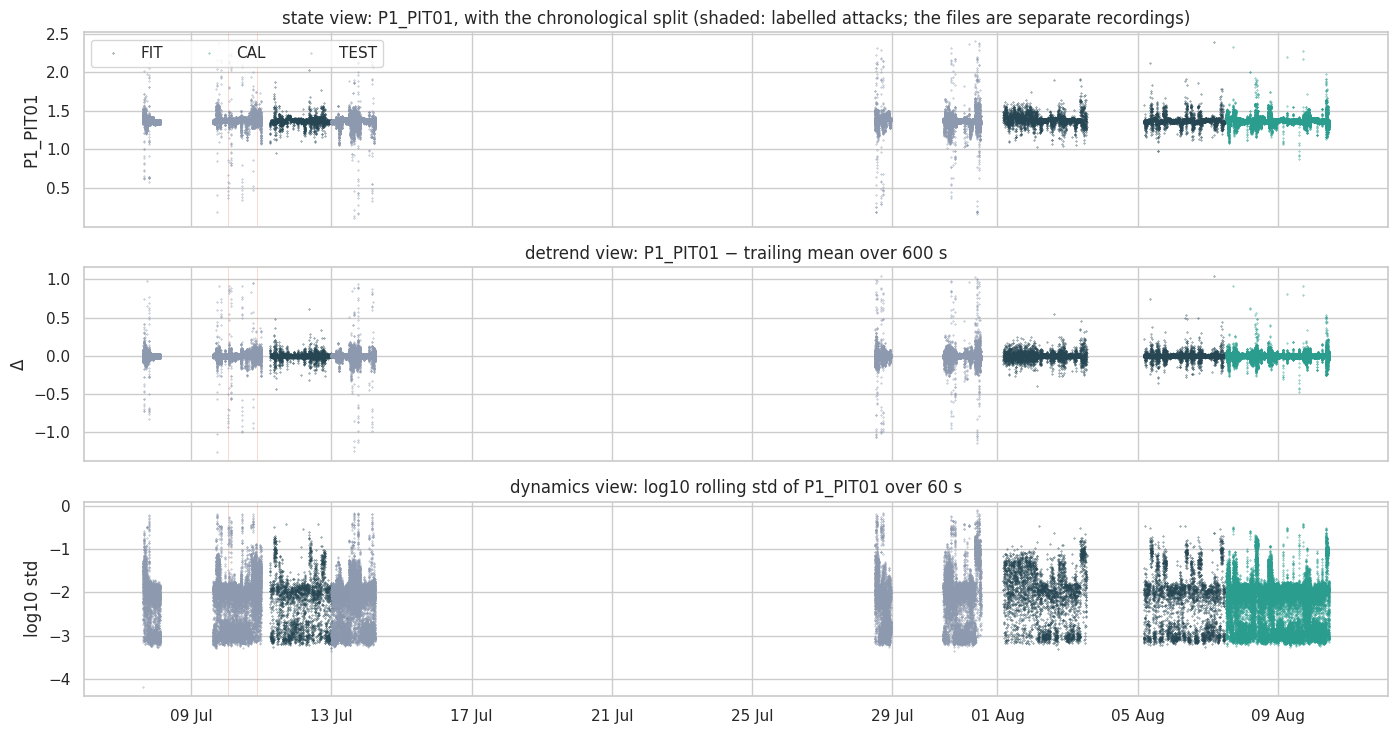

In [9]:
tag = "P1_PIT01" if "P1_PIT01" in CONTINUOUS else CONTINUOUS[0]
fig, axes = plt.subplots(3, 1, figsize=(14, 7.5), sharex=True)
for name, frame, color in [("FIT", fit_df.iloc[::60], "#264653"), ("CAL", cal_df, "#2a9d8f"), ("TEST", test_df, "#8d99ae")]:
    axes[0].plot(frame["timestamp"], frame[tag], ls='none', marker='.', ms=0.6, color=color, label=name)
    axes[1].plot(frame["timestamp"], frame[f"{tag}_dt{W}"], ls='none', marker='.', ms=0.6, color=color)
    axes[2].plot(frame["timestamp"], frame[f"{tag}_sd{WS}"], ls='none', marker='.', ms=0.6, color=color)
for ax in axes:
    shade_attacks(ax, segments)
axes[0].set(title=f"state view: {tag}, with the chronological split (shaded: labelled attacks; the files are separate recordings)", ylabel=tag)
axes[1].set(title=f"detrend view: {tag} − trailing mean over {W} s", ylabel="Δ")
axes[2].set(title=f"dynamics view: log10 rolling std of {tag} over {WS} s", ylabel="log10 std")
axes[0].legend(loc="upper left", ncol=3)
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.tight_layout()
save_fig(fig, "split_and_views")
plt.show()

### **3.1 Drift per feature and view**

Two descriptive measures, neither used for selection: the KS statistic between FIT and normal TEST rows, and the fraction of TEST rows outside the FIT range.

In [10]:
test_normal_rows = test_df.loc[test_df["is_attack"] == 0]
drift = pd.DataFrame([
    {"feature": f, "view": v,
     "ks_fit_vs_cal": stats.ks_2samp(fit_df[f].iloc[::10], cal_df[f]).statistic,
     "ks_fit_vs_test_normal": stats.ks_2samp(fit_df[f].iloc[::10], test_normal_rows[f]).statistic,
     "test_outside_fit_range": ((test_df[f] < fit_df[f].min()) | (test_df[f] > fit_df[f].max())).mean()}
    for v, feats in VIEW_FEATURES.items() for f in feats
])
drift.to_csv(RUN_DIR / "drift_per_feature.csv", index=False)
display(drift.groupby("view")[["ks_fit_vs_cal", "ks_fit_vs_test_normal", "test_outside_fit_range"]].agg(["mean", "max"]).round(3))
for v, feats in VIEW_FEATURES.items():
    outside = np.any([(test_df[f] < fit_df[f].min()) | (test_df[f] > fit_df[f].max()) for f in feats], axis=0).mean()
    print(f"{v:9s}: TEST rows with ≥1 feature outside the FIT range: {outside:.1%}")

ks_fit_vs_cal        ks_fit_vs_test_normal         \
                  mean    max                  mean    max   
view                                                         
detrend          0.036  0.147                 0.024  0.154   
dynamics         0.094  0.361                 0.072  0.329   
state            0.111  0.404                 0.088  0.535   

         test_outside_fit_range         
                           mean    max  
view                                    
detrend                   0.002  0.020  
dynamics                  0.002  0.009  
state                     0.003  0.084

state    : TEST rows with ≥1 feature outside the FIT range: 12.8%
detrend  : TEST rows with ≥1 feature outside the FIT range: 4.0%
dynamics : TEST rows with ≥1 feature outside the FIT range: 2.5%


## **4. Teacher contexts and scalers**

Each seed draws a **time-stratified** context of `context_size` FIT rows, one random row per consecutive time bin. The same row indices are used for every view. One `StandardScaler` per view is fitted on FIT and shared by TabPFN and the GMM.

In [11]:
def time_stratified_context(n_rows, size, seed):
    rng = np.random.default_rng(seed)
    bins = np.array_split(np.arange(n_rows), size)
    return np.array([rng.choice(b) for b in bins if len(b)])


context_indices = {s: time_stratified_context(len(fit_df), TEACHER_CONFIG["context_size"], s)
                   for s in TEACHER_CONFIG["teacher_seeds"]}
view_scalers = {v: StandardScaler().fit(fit_df[f].to_numpy(np.float32)) for v, f in VIEW_FEATURES.items()}


def scaled(view, frame):
    return view_scalers[view].transform(frame[VIEW_FEATURES[view]].to_numpy(np.float32)).astype(np.float32)


rows_per_member = len(cal_df) + len(test_df)
est_min = {v: TABPFN_MS_PER_ROW_FEATURE * len(f) * rows_per_member / 60000 for v, f in VIEW_FEATURES.items()}
n_seeds = len(TEACHER_CONFIG["teacher_seeds"])
print("Context sizes:", {s: len(i) for s, i in context_indices.items()})
print(f"Rows to score per (view, seed): cal={len(cal_df):,} + test={len(test_df):,}")
print("Estimated TabPFN minutes per seed:", {v: round(m) for v, m in est_min.items()},
      f"→ total ≈ {sum(est_min.values()) * n_seeds / 60:.1f} h for {n_seeds} seeds (cached per member)")

Context sizes: {42: 5000, 43: 5000, 44: 5000}
Rows to score per (view, seed): cal=25,345 + test=40,201
Estimated TabPFN minutes per seed: {'state': 34, 'detrend': 33, 'dynamics': 33} → total ≈ 5.0 h for 3 seeds (cached per member)


## **Part B — TabPFN density teachers, one per view**

For each view and seed, `TabPFNUnsupervisedModel` is fitted on that seed's context, and the chain-rule log-density is computed for CAL and TEST.

- **Score** = −log-density, turned into a robust z-score per member against its own CAL scores: (s − median_CAL) / IQR_CAL.
- **View teacher** = mean over seeds.
- **Fusions** are computed identically for TabPFN and the GMM: `fused` = mean of the three views (the SWaT v3 primary), `fused-sd` = mean of state + dynamics, and `fused-max` = max over the three views.
- **Caching.** Each (view, seed) member is saved in `teacher/<teacher_fp>/members/` as soon as it is done, so an interrupted run resumes where it stopped.

In [12]:
class DensityCompatibleTabPFNRegressor(TabPFNRegressor):
    # Align full-output logits with the density criterion's bin boundaries.

    def predict(self, X, **kwargs):
        prediction = super().predict(X, **kwargs)
        if kwargs.get("output_type") == "full":
            # TabPFN can return float32 logits with float64 borders, which makes
            # BarDistribution fail inside the extension; align dtype and device.
            borders = prediction["criterion"].borders
            prediction = dict(prediction)
            prediction["logits"] = torch.as_tensor(prediction["logits"]).to(
                dtype=borders.dtype, device=borders.device
            )
        return prediction


def finite_anomaly_score(log_density):
    values = np.asarray(log_density, dtype=np.float64)
    finite = values[np.isfinite(values)]
    if finite.size == 0:
        return np.zeros_like(values)
    clean = np.nan_to_num(values, nan=finite.min(), neginf=finite.min(), posinf=finite.max())
    return -clean


def score_in_batches(model, X, batch_size, n_permutations, permutation_seed):
    chunks = []
    for start in range(0, len(X), batch_size):
        random.seed(permutation_seed)          # same chain-rule orders for every batch
        result = model.outliers(
            torch.as_tensor(X[start:start + batch_size], dtype=torch.float32),
            n_permutations=n_permutations,
        )
        chunks.append(result.detach().cpu().numpy() if torch.is_tensor(result) else np.asarray(result))
    return finite_anomaly_score(np.concatenate(chunks))


def make_teacher(seed):
    kw = dict(n_estimators=TEACHER_CONFIG["n_estimators"], device=DEVICE, random_state=seed,
              memory_saving_mode="auto", show_progress_bar=False)
    return TabPFNUnsupervisedModel(tabpfn_clf=TabPFNClassifier(**kw), tabpfn_reg=DensityCompatibleTabPFNRegressor(**kw))

In [13]:
%%time
SPLITS = {"cal": cal_df, "test": test_df}
teacher_members = {}          # (view, seed) -> {split: scores, f"sec_{split}": seconds}
tabpfn_checkpoint = None

for view in VIEW_FEATURES:
    X_pool = scaled(view, fit_df)
    X_splits = {name: scaled(view, frame) for name, frame in SPLITS.items()}
    for seed in TEACHER_CONFIG["teacher_seeds"]:
        path = TEACHER_DIR / "members" / f"{view}_seed_{seed}.npz"
        member = dict(np.load(path)) if path.exists() else {}
        missing = [s for s in X_splits if s not in member]
        if not missing:
            print(f"{view:9s} seed {seed}: loaded from cache")
            teacher_members[(view, seed)] = member
            continue

        torch.manual_seed(seed)
        model = make_teacher(seed)
        model.fit(X_pool[context_indices[seed]])
        for split in missing:
            t0 = time.time()
            member[split] = score_in_batches(model, X_splits[split], TEACHER_CONFIG["score_batch_size"],
                                             TEACHER_CONFIG["n_permutations"], permutation_seed=seed)
            member[f"sec_{split}"] = np.array(time.time() - t0)
            print(f"{view:9s} seed {seed}: scored {split:5s} ({len(X_splits[split]):,} rows × {X_splits[split].shape[1]} features) "
                  f"in {float(member[f'sec_{split}']) / 60:.1f} min")
            np.savez(path, **member)
        teacher_members[(view, seed)] = member

        if tabpfn_checkpoint is None:
            configs = getattr(getattr(model, "tabpfn_reg", None), "configs_", None) or []
            tabpfn_checkpoint = getattr(configs[0], "name", None) if configs else None
        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

if tabpfn_checkpoint:
    record = json.loads(teacher_config_path.read_text())
    record["tabpfn_checkpoint"] = tabpfn_checkpoint
    teacher_config_path.write_text(json.dumps(record, indent=2))
print("TabPFN checkpoint:", json.loads(teacher_config_path.read_text()).get("tabpfn_checkpoint"))

state     seed 42: scored cal   (25,345 rows × 48 features) in 13.4 min
state     seed 42: scored test  (40,201 rows × 48 features) in 19.9 min
state     seed 43: scored cal   (25,345 rows × 48 features) in 13.5 min
state     seed 43: scored test  (40,201 rows × 48 features) in 20.0 min
state     seed 44: scored cal   (25,345 rows × 48 features) in 13.5 min
state     seed 44: scored test  (40,201 rows × 48 features) in 20.0 min
detrend   seed 42: scored cal   (25,345 rows × 47 features) in 13.0 min
detrend   seed 42: scored test  (40,201 rows × 47 features) in 19.3 min
detrend   seed 43: scored cal   (25,345 rows × 47 features) in 13.0 min
detrend   seed 43: scored test  (40,201 rows × 47 features) in 19.4 min
detrend   seed 44: scored cal   (25,345 rows × 47 features) in 13.0 min
detrend   seed 44: scored test  (40,201 rows × 47 features) in 19.3 min
dynamics  seed 42: scored cal   (25,345 rows × 47 features) in 13.1 min
dynamics  seed 42: scored test  (40,201 rows × 47 features) in 1

### **B1. Calibrate, fuse and save the teacher scores**

| File | Rows | Contents |
|---|---|---|
| `teacher/<fp>/teacher_cal.parquet` | later normal rows, no labels | timestamp, all view features, `teacher_<view>`, per-seed columns, `teacher_fused`, `teacher_fused-sd`, `teacher_fused-max` |
| `teacher/<fp>/teacher_test.parquet` | attack period | same + `is_attack`, `attack_id` |

In [14]:
seeds = TEACHER_CONFIG["teacher_seeds"]
views = list(VIEW_FEATURES)
FUSIONS = {name: [v for v in members if v in views] for name, members in EVAL_CONFIG["fusions"].items()}


def add_fusions(per_view):
    # The same fusion rule for TabPFN and the GMM: inputs are CAL-calibrated robust z-scores per view.
    out = dict(per_view)
    for name, members in FUSIONS.items():
        out[name] = np.mean([per_view[v] for v in members], axis=0)
    out["fused-max"] = np.max([per_view[v] for v in views], axis=0)
    return out


member_z = {(v, s, split): robust_z(teacher_members[(v, s)][split], teacher_members[(v, s)]["cal"])
            for v in views for s in seeds for split in SPLITS}
teacher_files = {}
for split, frame in SPLITS.items():
    extra = ["is_attack", "attack_id"] if split == "test" else []
    out = frame[["timestamp"] + ALL_FEATURES + extra].copy()
    per_view = {v: np.mean([member_z[(v, s, split)] for s in seeds], axis=0) for v in views}
    for name, scores in add_fusions(per_view).items():
        out[f"teacher_{name}"] = scores
    for v in views:
        for s in seeds:
            out[f"teacher_{v}_seed_{s}"] = member_z[(v, s, split)]
    out.attrs = {}
    out.to_parquet(TEACHER_DIR / f"teacher_{split}.parquet", index=False)
    teacher_files[split] = out
segments.to_csv(TEACHER_DIR / "attack_segments.csv", index=False)
(TEACHER_DIR / "features.json").write_text(json.dumps({"views": VIEW_FEATURES, "all": ALL_FEATURES}))

teacher_cost = pd.DataFrame([
    {"view": v, "seed": s, "n_features": len(VIEW_FEATURES[v]),
     "seconds": sum(float(teacher_members[(v, s)].get(f"sec_{k}", np.nan)) for k in SPLITS),
     "rows_scored": rows_per_member} for v in views for s in seeds
])
teacher_cost["ms_per_row"] = 1000 * teacher_cost["seconds"] / teacher_cost["rows_scored"]
teacher_cost.to_csv(TEACHER_DIR / "teacher_cost.csv", index=False)
print("Saved teacher scores to", TEACHER_DIR.resolve())
display(teacher_cost.round(2))

Saved teacher scores to /home/jaume/_DEVELOPMENT/_projects/tabular-IDS/results/HAI_full_pipeline_v1/teacher/3998d76cb7


,view,seed,n_features,seconds,rows_scored,ms_per_row
0,state,42,48,2003.42,65546,30.57
1,state,43,48,2013.90,65546,30.72
2,state,44,48,2009.97,65546,30.67
3,detrend,42,47,1937.93,65546,29.57
4,detrend,43,47,1946.04,65546,29.69
5,detrend,44,47,1937.98,65546,29.57
6,dynamics,42,47,1951.31,65546,29.77
7,dynamics,43,47,1939.93,65546,29.60
8,dynamics,44,47,1943.35,65546,29.65


### **B2. Teacher results at the static CAL threshold**

,threshold,roc_auc,average_precision,precision,recall,f1,test_fpr,accuracy,recall_onset,recall_sustained
teacher,,,,,,,,,,
teacher_state,1.6954,0.8891,0.4698,0.2262,0.6212,0.3316,0.0479,0.9448,0.5661,0.6486
teacher_detrend,2.3057,0.8763,0.2644,0.2313,0.2818,0.2541,0.0211,0.9635,0.1831,0.3311
teacher_dynamics,2.1641,0.8888,0.2425,0.3912,0.3224,0.3535,0.0113,0.9740,0.2983,0.3345
teacher_fused,1.5537,0.9143,0.4435,0.3843,0.5784,0.4617,0.0209,0.9702,0.5017,0.6166
teacher_fused-sd,1.5819,0.9177,0.4375,0.3982,0.5908,0.4757,0.0201,0.9713,0.5017,0.6351
teacher_fused-max,2.5657,0.8952,0.3216,0.3118,0.4577,0.3709,0.0228,0.9657,0.4034,0.4848


,mean,std,min,max
view,,,,
detrend,0.8754,0.0038,0.8722,0.8796
dynamics,0.8847,0.0100,0.8755,0.8954
state,0.8843,0.0033,0.8806,0.8869


figure saved: output-figures/teacher_roc_daily_hai2103_v1.png


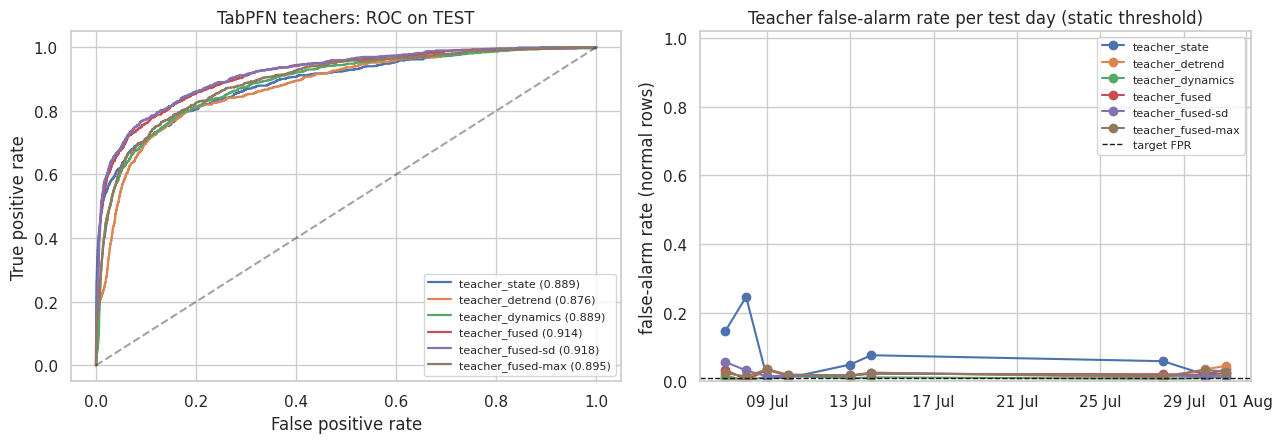

In [15]:
tt, tc = teacher_files["test"], teacher_files["cal"]
teacher_variants = [f"teacher_{v}" for v in views] + [f"teacher_{f}" for f in FUSIONS] + ["teacher_fused-max"]

phase = np.full(len(tt), "normal", dtype=object)
for seg in segments.itertuples(index=False):
    inside = tt["timestamp"].between(seg.start, seg.end).to_numpy()
    since = (tt["timestamp"] - seg.start).dt.total_seconds().to_numpy()
    phase[inside] = np.where(since[inside] < EVAL_CONFIG["onset_s"], "onset", "sustained")

rows = []
for col in teacher_variants:
    thr = threshold_from_calibration(tc[col], EVAL_CONFIG["target_fpr"])
    pred = tt[col].to_numpy() >= thr
    rows.append({"teacher": col, "threshold": thr, **point_metrics(y_test, tt[col], thr),
                 "recall_onset": pred[phase == "onset"].mean(), "recall_sustained": pred[phase == "sustained"].mean()})
display(pd.DataFrame(rows).set_index("teacher").round(4))

seed_auc = pd.DataFrame([{"view": v, "seed": s, "roc_auc": roc_auc_score(y_test, tt[f"teacher_{v}_seed_{s}"])}
                         for v in views for s in seeds])
display(seed_auc.groupby("view")["roc_auc"].agg(["mean", "std", "min", "max"]).round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for col in teacher_variants:
    f, t_, _ = roc_curve(y_test, tt[col])
    axes[0].plot(f, t_, lw=1.6, label=f"{col} ({roc_auc_score(y_test, tt[col]):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="TabPFN teachers: ROC on TEST")
axes[0].legend(fontsize=8)
for col in teacher_variants:
    thr = threshold_from_calibration(tc[col], EVAL_CONFIG["target_fpr"])
    daily = daily_false_alarm_rate(tt["timestamp"], y_test, tt[col] >= thr)
    axes[1].plot(pd.to_datetime(daily.index), daily.values, marker="o", label=col)
axes[1].axhline(EVAL_CONFIG["target_fpr"], color="k", ls="--", lw=1, label="target FPR")
axes[1].set(ylabel="false-alarm rate (normal rows)", title="Teacher false-alarm rate per test day (static threshold)", ylim=(0, 1.02))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[1].legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "teacher_roc_daily")
plt.show()

## **Part D — Gaussian mixture density baseline (same features, scaler, calibration and fusion)**

One full-covariance GMM per view is fitted on a FIT subsample (every 20 s), with *k* chosen by BIC over {4, …, 128} and the score = −log p. Scores are calibrated (robust z against CAL) and fused **exactly like the teacher**, so `TabPFN <x> − GMM <x>` isolates what the foundation-model density adds.

In [16]:
%%time
gmm_raw, gmm_rows, bic_rows = {}, [], []
for view in views:
    X_fit = scaled(view, fit_df)[::GMM_CONFIG["fit_stride"]]
    best = None
    for k in GMM_CONFIG["components_grid"]:
        t0 = time.perf_counter()
        gmm = GaussianMixture(k, covariance_type=GMM_CONFIG["covariance"], reg_covar=GMM_CONFIG["reg_covar"],
                              random_state=GMM_CONFIG["seed"]).fit(X_fit)
        bic = gmm.bic(X_fit)
        bic_rows.append({"view": view, "k": k, "bic": bic, "fit_seconds": time.perf_counter() - t0})
        if best is None or bic < best[0]:
            best = (bic, k, gmm)
    _, k, gmm = best
    if k == max(GMM_CONFIG["components_grid"]):
        print(f"WARNING: GMM {view}: BIC still prefers the largest k = {k}; consider extending the grid.")
    X_test_view = scaled(view, test_df)
    t0 = time.perf_counter()
    test_scores = -gmm.score_samples(X_test_view)
    ms_per_row = 1000 * (time.perf_counter() - t0) / len(X_test_view)
    gmm_raw[view] = {"cal": -gmm.score_samples(scaled(view, cal_df)), "test": test_scores}
    thr = threshold_from_calibration(gmm_raw[view]["cal"], EVAL_CONFIG["target_fpr"])
    point = point_metrics(y_test, gmm_raw[view]["test"], thr)
    gmm_rows.append({"view": view, "k": k, "n_features": X_fit.shape[1], "ms_per_row_batched": ms_per_row, **point})
    print(f"GMM {view:9s} k={k:2d}  AUC={point['roc_auc']:.4f}  test FPR={point['test_fpr']:.3f}  recall={point['recall']:.3f}")

gmm_out = {split: add_fusions({v: robust_z(gmm_raw[v][split], gmm_raw[v]["cal"]) for v in views}) for split in SPLITS}
for name in gmm_out["test"]:
    for split in SPLITS:
        pd.DataFrame({"score": gmm_out[split][name]}).to_parquet(RUN_DIR / f"gmm_{name}_{split}.parquet", index=False)
pd.DataFrame(gmm_rows).to_csv(RUN_DIR / "gmm_summary.csv", index=False)
pd.DataFrame(bic_rows).to_csv(RUN_DIR / "gmm_bic.csv", index=False)
display(pd.DataFrame(gmm_rows).set_index("view").round(4))
display(pd.DataFrame(bic_rows).pivot(index="k", columns="view", values="bic").round(0))

GMM state     k=48  AUC=0.8698  test FPR=0.035  recall=0.589
GMM detrend   k=32  AUC=0.9025  test FPR=0.039  recall=0.707
GMM dynamics  k=32  AUC=0.8938  test FPR=0.011  recall=0.423


,k,n_features,ms_per_row_batched,roc_auc,average_precision,precision,recall,f1,test_fpr,accuracy
view,,,,,,,,,,
state,48,48,0.0022,0.8698,0.2896,0.2763,0.5885,0.3761,0.0348,0.9569
detrend,32,47,0.0022,0.9025,0.3413,0.2922,0.7069,0.4135,0.0386,0.9557
dynamics,32,47,0.0015,0.8938,0.3252,0.4635,0.4228,0.4422,0.0110,0.9765


view,detrend,dynamics,state
k,,,
4,-330420.0,597451.0,123803.0
8,-581328.0,240453.0,-396546.0
16,-734649.0,118360.0,-747822.0
32,-747360.0,68056.0,-925946.0
48,-649810.0,106467.0,-950595.0
64,-535383.0,234744.0,-933948.0
96,-180045.0,460412.0,-760569.0
128,57439.0,785171.0,-530900.0


CPU times: user 3h 32min 41s, sys: 12.6 s, total: 3h 32min 54s
Wall time: 16min 33s


## **E. Evaluation: every table rebuilt from the saved files**

This section reloads only the saved score files. For each family (TabPFN and GMM) it evaluates: **fused (primary)**, fused-sd, fused-max, state, detrend and dynamics. Two thresholds are applied to every method:
- **static**: the CAL 1% quantile;
- **adaptive**: the score normalised by its trailing-24 h median/IQR (label-free), then thresholded at the CAL quantile of the normalised score.

In [17]:
cfg = json.loads((RUN_DIR / "config.json").read_text())
ecfg = cfg["eval_config"]
target_fpr = ecfg["target_fpr"]
stride_s = cfg["teacher_config"]["test_stride"]
ev_test = pd.read_parquet(TEACHER_DIR / "teacher_test.parquet")
ev_cal = pd.read_parquet(TEACHER_DIR / "teacher_cal.parquet")
ev_segments = pd.read_csv(TEACHER_DIR / "attack_segments.csv", parse_dates=["start", "end"], dtype={"attack_id": str})
y_eval = ev_test["is_attack"].to_numpy().astype(int)
ts_eval = ev_test["timestamp"]
view_names = list(json.loads((TEACHER_DIR / "features.json").read_text())["views"])
GROUPS = [ecfg["primary"]] + [f for f in ecfg["fusions"] if f != ecfg["primary"]] + ["fused-max"] + view_names

METHODS = {}
for family in ["TabPFN", "GMM"]:
    for g in GROUPS:
        if family == "TabPFN":
            METHODS[f"TabPFN {g}"] = (ev_test[f"teacher_{g}"].to_numpy(), ev_cal[f"teacher_{g}"].to_numpy())
        else:
            METHODS[f"GMM {g}"] = (pd.read_parquet(RUN_DIR / f"gmm_{g}_test.parquet")["score"].to_numpy(),
                                   pd.read_parquet(RUN_DIR / f"gmm_{g}_cal.parquet")["score"].to_numpy())
names = list(METHODS)
PRIMARY = {"TabPFN": f"TabPFN {ecfg['primary']}", "GMM": f"GMM {ecfg['primary']}"}
CORE = [f"{fam} {g}" for g in [ecfg["primary"], "fused-sd"] for fam in ["TabPFN", "GMM"] if f"{fam} {g}" in METHODS]
score_matrix = {m: METHODS[m][0] for m in names}
THRESHOLDS = {m: threshold_from_calibration(cal, target_fpr) for m, (_, cal) in METHODS.items()}

ADAPTIVE = {}
for m, (test_s, cal_s) in METHODS.items():
    z_cal, z_test = adaptive_normalise(cal_s, test_s, stride_s, ecfg)
    ADAPTIVE[m] = (z_test, threshold_from_calibration(z_cal, target_fpr))

phase_eval = np.full(len(ev_test), "normal", dtype=object)
for seg in ev_segments.itertuples(index=False):
    inside = ts_eval.between(seg.start, seg.end).to_numpy()
    since = (ts_eval - seg.start).dt.total_seconds().to_numpy()
    phase_eval[inside] = np.where(since[inside] < ecfg["onset_s"], "onset", "sustained")

family_color = {"TabPFN": "#1d3557", "GMM": "#e76f51"}
method_colors = dict(zip(names, sns.color_palette("tab20", len(names))))
print(f"Run {cfg['run_id']} | run {cfg['run_fingerprint']} | teacher {cfg['teacher_fingerprint']}")
print(f"TEST rows: {len(y_eval):,} ({y_eval.sum():,} attack, {y_eval.mean():.1%}) | events: {len(ev_segments)} | target FPR {target_fpr}")
print(f"Methods ({len(names)}): {names}")

Run HAI_full_pipeline_v1 | run 7fbfd28556 | teacher 3998d76cb7
TEST rows: 40,201 (887 attack, 2.2%) | events: 50 | target FPR 0.01
Methods (12): ['TabPFN fused', 'TabPFN fused-sd', 'TabPFN fused-max', 'TabPFN state', 'TabPFN detrend', 'TabPFN dynamics', 'GMM fused', 'GMM fused-sd', 'GMM fused-max', 'GMM state', 'GMM detrend', 'GMM dynamics']


### **E1. Point-wise and event-wise results: static vs. adaptive threshold**

`recall_onset` and `recall_sustained` split attack rows into the first 5 min of each attack and the rest.

In [18]:
rows, per_event_tables = [], {}
for method in names:
    for mode, (scores, thr) in {"static": (score_matrix[method], THRESHOLDS[method]),
                                "adaptive": ADAPTIVE[method]}.items():
        pred = scores >= thr
        point = point_metrics(y_eval, np.nan_to_num(scores, nan=-np.inf), thr)
        event, per_event = event_metrics(ts_eval, y_eval, pred, ev_segments)
        per_event_tables[(method, mode)] = per_event
        rows.append({"method": method, "threshold_mode": mode, "threshold": thr, **point, **event,
                     "recall_onset": pred[phase_eval == "onset"].mean(),
                     "recall_sustained": pred[phase_eval == "sustained"].mean()})
main_results = pd.DataFrame(rows)
main_results.insert(0, "run_fingerprint", cfg["run_fingerprint"])
main_results.to_csv(RUN_DIR / "results_main.csv", index=False)
show_cols = ["roc_auc", "average_precision", "test_fpr", "recall", "recall_onset", "recall_sustained", "precision",
             "f1", "attacks_detected", "false_alarm_episodes", "composite_f1", "median_ttd_s"]
for mode in ["static", "adaptive"]:
    print(f"--- {mode} threshold ---")
    display(main_results[main_results["threshold_mode"] == mode].set_index("method")[show_cols].round(4))

--- static threshold ---


,roc_auc,average_precision,test_fpr,recall,recall_onset,recall_sustained,precision,f1,attacks_detected,false_alarm_episodes,composite_f1,median_ttd_s
method,,,,,,,,,,,,
TabPFN fused,0.9143,0.4435,0.0209,0.5784,0.5017,0.6166,0.3843,0.4617,42,213,0.5273,26.0
TabPFN fused-sd,0.9177,0.4375,0.0201,0.5908,0.5017,0.6351,0.3982,0.4757,43,285,0.5443,26.0
TabPFN fused-max,0.8952,0.3216,0.0228,0.4577,0.4034,0.4848,0.3118,0.3709,39,184,0.4455,26.0
TabPFN state,0.8891,0.4698,0.0479,0.6212,0.5661,0.6486,0.2262,0.3316,45,933,0.3615,16.0
TabPFN detrend,0.8763,0.2644,0.0211,0.2818,0.1831,0.3311,0.2313,0.2541,28,82,0.3273,46.5
TabPFN dynamics,0.8888,0.2425,0.0113,0.3224,0.2983,0.3345,0.3912,0.3535,32,88,0.4856,36.5
GMM fused,0.8997,0.3036,0.0562,0.7542,0.6983,0.7821,0.2324,0.3553,47,215,0.3726,16.0
GMM fused-sd,0.9011,0.2991,0.0396,0.7091,0.6576,0.7348,0.2879,0.4095,46,186,0.4385,15.5
GMM fused-max,0.8864,0.2812,0.0574,0.7024,0.6814,0.7128,0.2163,0.3308,46,195,0.3503,15.5


--- adaptive threshold ---


,roc_auc,average_precision,test_fpr,recall,recall_onset,recall_sustained,precision,f1,attacks_detected,false_alarm_episodes,composite_f1,median_ttd_s
method,,,,,,,,,,,,
TabPFN fused,0.9019,0.3729,0.0273,0.5254,0.4746,0.5507,0.3024,0.3839,41,307,0.4419,26.0
TabPFN fused-sd,0.9049,0.3568,0.0217,0.4994,0.4949,0.5017,0.3413,0.4055,43,288,0.4887,26.0
TabPFN fused-max,0.8838,0.2868,0.0160,0.3529,0.3186,0.3699,0.3323,0.3423,34,130,0.4464,32.5
TabPFN state,0.8821,0.3621,0.0131,0.4070,0.4102,0.4054,0.4121,0.4095,41,269,0.5485,27.0
TabPFN detrend,0.8701,0.2450,0.0174,0.2424,0.1492,0.2889,0.2392,0.2408,22,68,0.3099,46.0
TabPFN dynamics,0.8833,0.2259,0.0139,0.3517,0.3220,0.3666,0.3628,0.3572,33,130,0.4682,37.0
GMM fused,0.9012,0.2980,0.0525,0.7170,0.6746,0.7382,0.2355,0.3545,46,213,0.3750,16.0
GMM fused-sd,0.9027,0.2951,0.0363,0.6460,0.6508,0.6436,0.2864,0.3968,46,173,0.4368,16.0
GMM fused-max,0.8851,0.2751,0.0495,0.6212,0.6271,0.6182,0.2208,0.3257,46,143,0.3561,16.0


#### **Confusion matrices: real vs. predicted (core methods)**

Rows are the **real** label and columns are the **predicted** label, on TEST rows (1 every 10 s). Each cell shows the count and the share of its real class:
- **Normal → Attack** = the test FPR.
- **Attack → Attack** = the recall.

TN    FP   FN   TP  attacks_detected  \
method           threshold_mode                                            
TabPFN fused     static          38492   822  374  513                42   
                 adaptive        38239  1075  421  466                41   
TabPFN fused-sd  static          38522   792  363  524                43   
                 adaptive        38459   855  444  443                43   
TabPFN fused-max static          38418   896  481  406                39   
                 adaptive        38685   629  574  313                34   
TabPFN state     static          37429  1885  336  551                45   
                 adaptive        38799   515  526  361                41   
TabPFN detrend   static          38483   831  637  250                28   
                 adaptive        38630   684  672  215                22   
TabPFN dynamics  static          38869   445  601  286                32   
                 adaptive        38766   548  575  312                33   
GMM fused        static          37104  2210  218  669                47   
                 adaptive        37249  2065  251  636                46   
GMM fused-sd     static          37758  1556  258  629                46   
                 adaptive        37886  1428  314  573                46   
GMM fused-max    static          37057  2257  264  623                46   
                 adaptive        37369  1945  336  551                46   
GMM state        static          37947  1367  365  522                46   
                 adaptive        38095  1219  424  463                45   
GMM detrend      static          37795  1519  260  627                46   
                 adaptive        38005  1309  282  605                46   
GMM dynamics     static          38880   434  512  375                36   
                 adaptive        38788   526  456  431                39   

                                 false_alarm_episodes  
method           threshold_mode                        
TabPFN fused     static                           213  
                 adaptive                         307  
TabPFN fused-sd  static                           285  
                 adaptive                         288  
TabPFN fused-max static                           184  
                 adaptive                         130  
TabPFN state     static                           933  
                 adaptive                         269  
TabPFN detrend   static                            82  
                 adaptive                          68  
TabPFN dynamics  static                            88  
                 adaptive                         130  
GMM fused        static                           215  
                 adaptive                         213  
GMM fused-sd     static                           186  
                 adaptive                         173  
GMM fused-max    static                           195  
                 adaptive                         143  
GMM state        static                           140  
                 adaptive                         122  
GMM detrend      static                           170  
                 adaptive                         122  
GMM dynamics     static                            84  
                 adaptive                         118

figure saved: output-figures/confusion_matrices_hai2103_v1.png


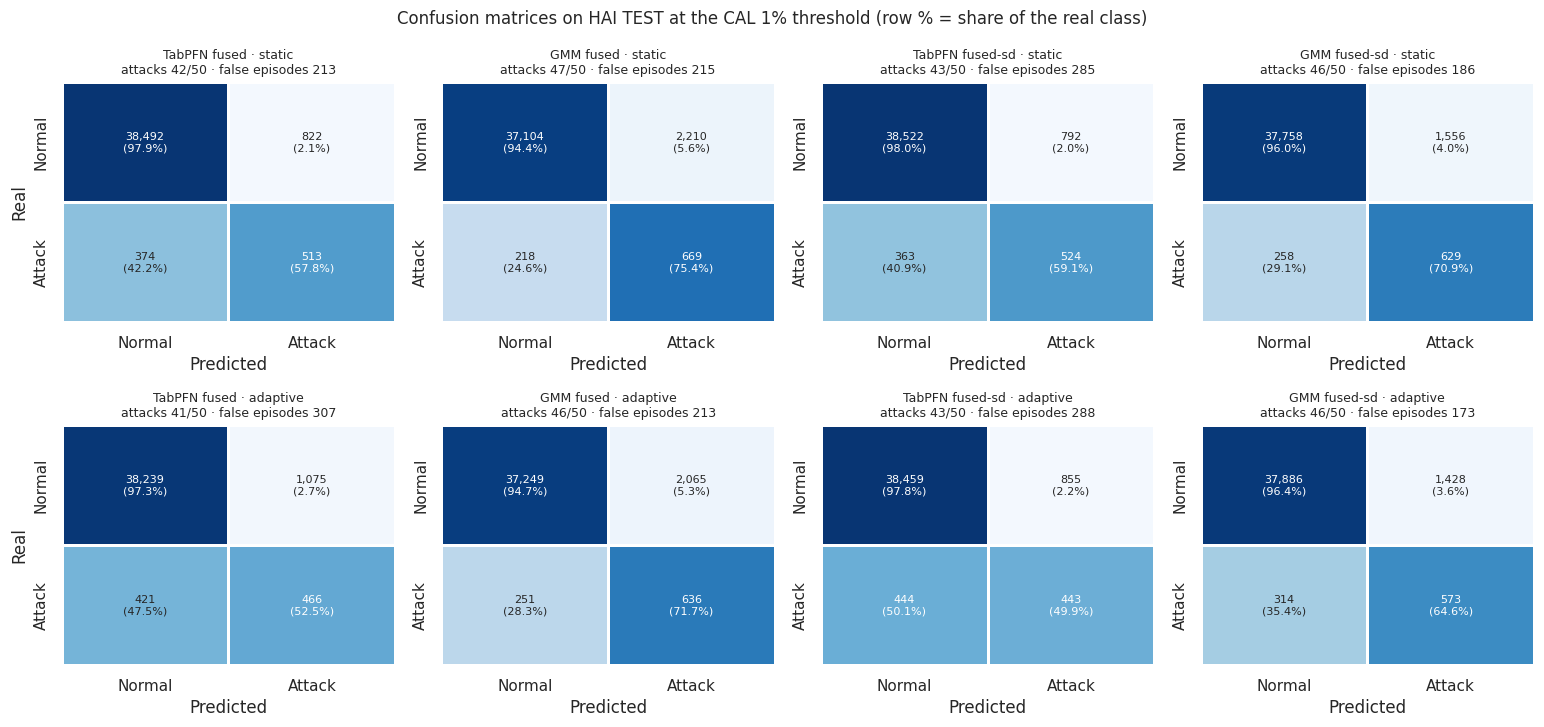

In [19]:
cm_rows = []
for method in names:
    for mode, (scores, thr) in {"static": (score_matrix[method], THRESHOLDS[method]), "adaptive": ADAPTIVE[method]}.items():
        tn, fp, fn, tp = confusion_matrix(y_eval, (scores >= thr).astype(int), labels=[0, 1]).ravel()
        r = main_results[(main_results["method"] == method) & (main_results["threshold_mode"] == mode)].iloc[0]
        cm_rows.append({"method": method, "threshold_mode": mode, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                        "attacks_detected": int(r["attacks_detected"]), "false_alarm_episodes": int(r["false_alarm_episodes"])})
confusion_table = pd.DataFrame(cm_rows)
confusion_table.to_csv(RUN_DIR / "results_confusion.csv", index=False)
display(confusion_table.set_index(["method", "threshold_mode"]))

fig, axes = plt.subplots(2, len(CORE), figsize=(3.9 * len(CORE), 7.4), squeeze=False)
for row_i, mode in enumerate(["static", "adaptive"]):
    for ax, m in zip(axes[row_i], CORE):
        r = confusion_table[(confusion_table["method"] == m) & (confusion_table["threshold_mode"] == mode)].iloc[0]
        counts = np.array([[r.TN, r.FP], [r.FN, r.TP]])
        share = counts / counts.sum(axis=1, keepdims=True)
        labels = np.array([[f"{c:,}\n({p:.1%})" for c, p in zip(cr, pr)] for cr, pr in zip(counts, share)])
        sns.heatmap(share, annot=labels, fmt="", annot_kws={"size": 8}, cmap="Blues", vmin=0, vmax=1, cbar=False,
                    linewidths=1, xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"], ax=ax)
        ax.grid(False)
        ax.set(xlabel="Predicted", ylabel="Real" if ax is axes[row_i][0] else "")
        ax.set_title(f"{m} · {mode}\nattacks {r.attacks_detected}/{len(ev_segments)} · false episodes {r.false_alarm_episodes}", fontsize=9)
fig.suptitle(f"Confusion matrices on HAI TEST at the CAL {target_fpr:.0%} threshold (row % = share of the real class)", fontsize=12)
plt.tight_layout()
save_fig(fig, "confusion_matrices")
plt.show()

### **E2. Several operating points (static threshold)**

In [20]:
grid_rows = []
for fpr_target in ecfg["fpr_grid"]:
    for method, (scores, cal) in METHODS.items():
        thr = threshold_from_calibration(cal, fpr_target)
        point = point_metrics(y_eval, scores, thr)
        event, _ = event_metrics(ts_eval, y_eval, scores >= thr, ev_segments)
        grid_rows.append({"target_fpr": fpr_target, "method": method, "test_fpr": point["test_fpr"],
                          "precision": point["precision"], "recall": point["recall"], "f1": point["f1"],
                          "attacks_detected": f"{event['attacks_detected']}/{event['attacks_total']}",
                          "composite_f1": event["composite_f1"], "median_ttd_s": event["median_ttd_s"]})
operating_points = pd.DataFrame(grid_rows)
operating_points.to_csv(RUN_DIR / "results_operating_points.csv", index=False)
display(operating_points.pivot(index="method", columns="target_fpr", values=["test_fpr", "recall", "attacks_detected"]).loc[names])

test_fpr                                  recall            \
target_fpr           0.005     0.010     0.020     0.050     0.005     0.010   
method                                                                         
TabPFN fused      0.010353  0.020909  0.037747  0.083889  0.480271  0.578354   
TabPFN fused-sd   0.009589  0.020145  0.041843  0.092817  0.485908  0.590755   
TabPFN fused-max  0.014575  0.022791   0.03963  0.090095   0.37655  0.457723   
TabPFN state      0.026708  0.047947  0.075902  0.135677  0.569335  0.621195   
TabPFN detrend    0.014397  0.021138   0.03238  0.069543  0.234498  0.281849   
TabPFN dynamics   0.007733  0.011319  0.018289  0.042606  0.219842  0.322435   
GMM fused         0.048609  0.056214  0.072112  0.109554   0.70575  0.754228   
GMM fused-sd      0.034288  0.039579  0.051279  0.096581  0.655017  0.709132   
GMM fused-max     0.052755   0.05741  0.065982   0.11314  0.664036  0.702368   
GMM state         0.030269  0.034771  0.063667  0.162232  0.553551  0.588501   
GMM detrend       0.030193  0.038638  0.050644  0.080607  0.666291  0.706877   
GMM dynamics       0.00758  0.011039   0.01867  0.039401  0.311161  0.422773   

                                     attacks_detected                       
target_fpr           0.020     0.050            0.005  0.010  0.020  0.050  
method                                                                      
TabPFN fused      0.647125  0.742954            37/50  42/50  45/50  46/50  
TabPFN fused-sd   0.669673  0.768884            39/50  43/50  46/50  49/50  
TabPFN fused-max  0.570462   0.70124            34/50  39/50  45/50  48/50  
TabPFN state      0.683202  0.745209            44/50  45/50  47/50  48/50  
TabPFN detrend    0.416009  0.631342            21/50  28/50  32/50  40/50  
TabPFN dynamics   0.434047  0.577227            29/50  32/50  40/50  43/50  
GMM fused         0.794814  0.844419            45/50  47/50  47/50  48/50  
GMM fused-sd      0.760992  0.815107            45/50  46/50  47/50  47/50  
GMM fused-max     0.745209  0.820744            46/50  46/50  46/50  47/50  
GMM state         0.724915  0.792559            46/50  46/50  47/50  48/50  
GMM detrend       0.746336  0.789177            45/50  46/50  47/50  47/50  
GMM dynamics      0.572717  0.678692            33/50  36/50  41/50  45/50

### **E3. Uncertainty: two bootstraps on the same replicates, and seeds**

- **Row-block bootstrap** (circular, 1 h blocks): keeps the autocorrelation intact. It treats the attack schedule as fixed.
- **Event bootstrap**: resamples the 14 attacks and the 1 h normal blocks separately, so it also captures *which* attacks happened. With so few attacks, this is the more honest interval, and the one used for the conclusions.

Every method is scored on the same replicate indices, so paired differences (§F2) come straight from these replicates.

In [21]:
%%time
rng = np.random.default_rng(ecfg["bootstrap_seed"])
block = ecfg["bootstrap_block_rows"]
attack_units = [np.arange(a, b) for a, b in contiguous_runs(y_eval == 1)]
normal_units = [np.arange(a, b)[i:i + block] for a, b in contiguous_runs(y_eval == 0) for i in range(0, b - a, block)]
print(f"Event bootstrap units: {len(attack_units)} attacks, {len(normal_units)} normal blocks")

boot = {"block": [], "event": []}
for _ in range(ecfg["bootstrap_repeats"]):
    for kind, idx in [("block", block_bootstrap_indices(len(y_eval), block, rng)),
                      ("event", event_bootstrap_indices(attack_units, normal_units, rng))]:
        yb = y_eval[idx]
        if yb.min() == yb.max():
            continue
        rec = {}
        for m in names:
            rec[f"auc|{m}"] = roc_auc_score(yb, score_matrix[m][idx])
            rec[f"ap|{m}"] = average_precision_score(yb, score_matrix[m][idx])
        boot[kind].append(rec)
boot = {k: pd.DataFrame(v) for k, v in boot.items()}
for kind, frame in boot.items():
    frame.to_parquet(RUN_DIR / f"bootstrap_replicates_{kind}.parquet", index=False)

ci_rows = []
for m in names:
    for metric, key, point in [("ROC-AUC", "auc", roc_auc_score(y_eval, score_matrix[m])),
                               ("Average precision", "ap", average_precision_score(y_eval, score_matrix[m]))]:
        row = {"method": m, "metric": metric, "estimate": point}
        for kind in boot:
            row[f"{kind}_ci_low"], row[f"{kind}_ci_high"] = np.quantile(boot[kind][f"{key}|{m}"], [0.025, 0.975])
        ci_rows.append(row)
ci_table = pd.DataFrame(ci_rows)
ci_table.to_csv(RUN_DIR / "results_bootstrap_ci.csv", index=False)
print({k: len(v) for k, v in boot.items()}, "replicates")
display(ci_table.set_index(["method", "metric"]).round(4))

seed_cols = [c for c in ev_test.columns if "_seed_" in c]
seed_table = pd.DataFrame([
    {"view": c.split("_seed_")[0].replace("teacher_", ""), "seed": c.split("_seed_")[1],
     "roc_auc": roc_auc_score(y_eval, ev_test[c]), "average_precision": average_precision_score(y_eval, ev_test[c])}
    for c in seed_cols
])
seed_table.to_csv(RUN_DIR / "results_teacher_seeds.csv", index=False)
display(seed_table.groupby("view")[["roc_auc", "average_precision"]].agg(["mean", "std", "min", "max"]).round(4))

Event bootstrap units: 50 attacks, 134 normal blocks
{'block': 1000, 'event': 1000} replicates


estimate  block_ci_low  block_ci_high  \
method           metric                                                     
TabPFN fused     ROC-AUC              0.9143        0.8806         0.9447   
                 Average precision    0.4435        0.3429         0.5364   
TabPFN fused-sd  ROC-AUC              0.9177        0.8850         0.9464   
                 Average precision    0.4375        0.3258         0.5524   
TabPFN fused-max ROC-AUC              0.8952        0.8555         0.9306   
                 Average precision    0.3216        0.2190         0.4226   
TabPFN state     ROC-AUC              0.8891        0.8470         0.9265   
                 Average precision    0.4698        0.3660         0.5742   
TabPFN detrend   ROC-AUC              0.8763        0.8351         0.9119   
                 Average precision    0.2644        0.1684         0.3616   
TabPFN dynamics  ROC-AUC              0.8888        0.8606         0.9165   
                 Average precision    0.2425        0.1683         0.3364   
GMM fused        ROC-AUC              0.8997        0.8603         0.9367   
                 Average precision    0.3036        0.2120         0.4093   
GMM fused-sd     ROC-AUC              0.9011        0.8643         0.9352   
                 Average precision    0.2991        0.2079         0.4731   
GMM fused-max    ROC-AUC              0.8864        0.8472         0.9259   
                 Average precision    0.2812        0.1891         0.3866   
GMM state        ROC-AUC              0.8698        0.8274         0.9089   
                 Average precision    0.2896        0.2017         0.4867   
GMM detrend      ROC-AUC              0.9025        0.8620         0.9377   
                 Average precision    0.3413        0.2569         0.4396   
GMM dynamics     ROC-AUC              0.8938        0.8566         0.9246   
                 Average precision    0.3252        0.2290         0.4541   

                                    event_ci_low  event_ci_high  
method           metric                                          
TabPFN fused     ROC-AUC                  0.8761         0.9454  
                 Average precision        0.3002         0.5757  
TabPFN fused-sd  ROC-AUC                  0.8809         0.9475  
                 Average precision        0.3213         0.5541  
TabPFN fused-max ROC-AUC                  0.8498         0.9322  
                 Average precision        0.1889         0.4678  
TabPFN state     ROC-AUC                  0.8406         0.9275  
                 Average precision        0.3516         0.5895  
TabPFN detrend   ROC-AUC                  0.8309         0.9127  
                 Average precision        0.1403         0.4070  
TabPFN dynamics  ROC-AUC                  0.8553         0.9179  
                 Average precision        0.1766         0.3435  
GMM fused        ROC-AUC                  0.8539         0.9353  
                 Average precision        0.1962         0.4379  
GMM fused-sd     ROC-AUC                  0.8565         0.9362  
                 Average precision        0.1981         0.5141  
GMM fused-max    ROC-AUC                  0.8372         0.9250  
                 Average precision        0.1782         0.4105  
GMM state        ROC-AUC                  0.8156         0.9101  
                 Average precision        0.1921         0.5134  
GMM detrend      ROC-AUC                  0.8565         0.9376  
                 Average precision        0.2312         0.4712  
GMM dynamics     ROC-AUC                  0.8507         0.9277  
                 Average precision        0.2309         0.4629

roc_auc                         average_precision                  \
            mean     std     min     max              mean     std     min   
view                                                                         
detrend   0.8754  0.0038  0.8722  0.8796            0.2637  0.0041  0.2590   
dynamics  0.8847  0.0100  0.8755  0.8954            0.2384  0.0168  0.2277   
state     0.8843  0.0033  0.8806  0.8869            0.4519  0.0177  0.4316   

                  
             max  
view              
detrend   0.2669  
dynamics  0.2578  
state     0.4644

CPU times: user 3min 47s, sys: 195 ms, total: 3min 47s
Wall time: 3min 47s


figure saved: output-figures/auc_ap_ci_all_methods_hai2103_v1.png


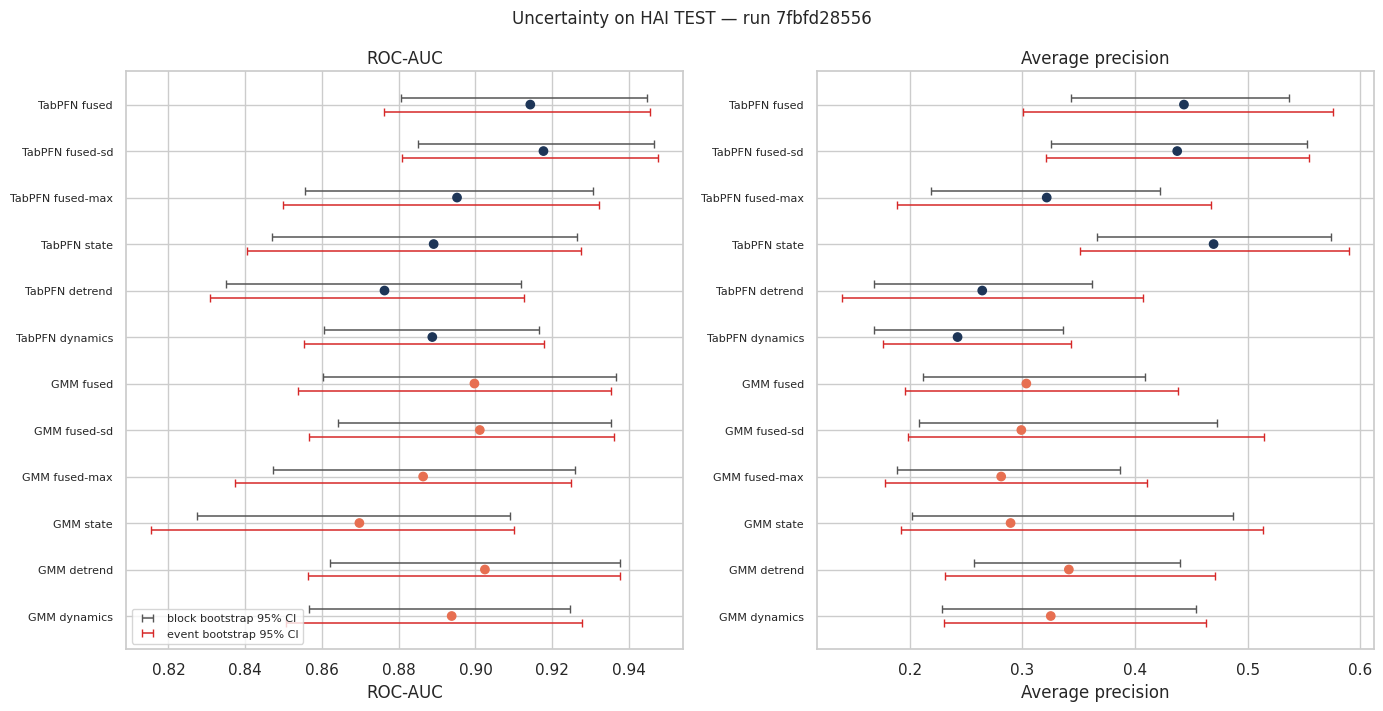

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 0.42 * len(names) + 2.2))
for ax, metric in zip(axes, ["ROC-AUC", "Average precision"]):
    view = ci_table[ci_table["metric"] == metric].set_index("method").loc[names]
    ypos = np.arange(len(view))
    for off, kind, color in [(-0.15, "block", "#555"), (0.15, "event", "#d62828")]:
        ax.errorbar(view["estimate"], ypos + off, xerr=[view["estimate"] - view[f"{kind}_ci_low"],
                    view[f"{kind}_ci_high"] - view["estimate"]], fmt="none", ecolor=color, capsize=3, lw=1.1,
                    label=f"{kind} bootstrap 95% CI")
    ax.scatter(view["estimate"], ypos, c=[family_color[m.split()[0]] for m in names], s=36, zorder=3)
    ax.set(yticks=ypos, xlabel=metric, title=metric)
    ax.set_yticklabels(names, fontsize=8)
    ax.invert_yaxis()
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle(f"Uncertainty on HAI TEST — run {cfg['run_fingerprint']}", fontsize=12)
plt.tight_layout()
save_fig(fig, "auc_ap_ci_all_methods")
plt.show()

### **E4. Per-attack detection (static threshold)**

figure saved: output-figures/per_attack_coverage_hai2103_v1.png


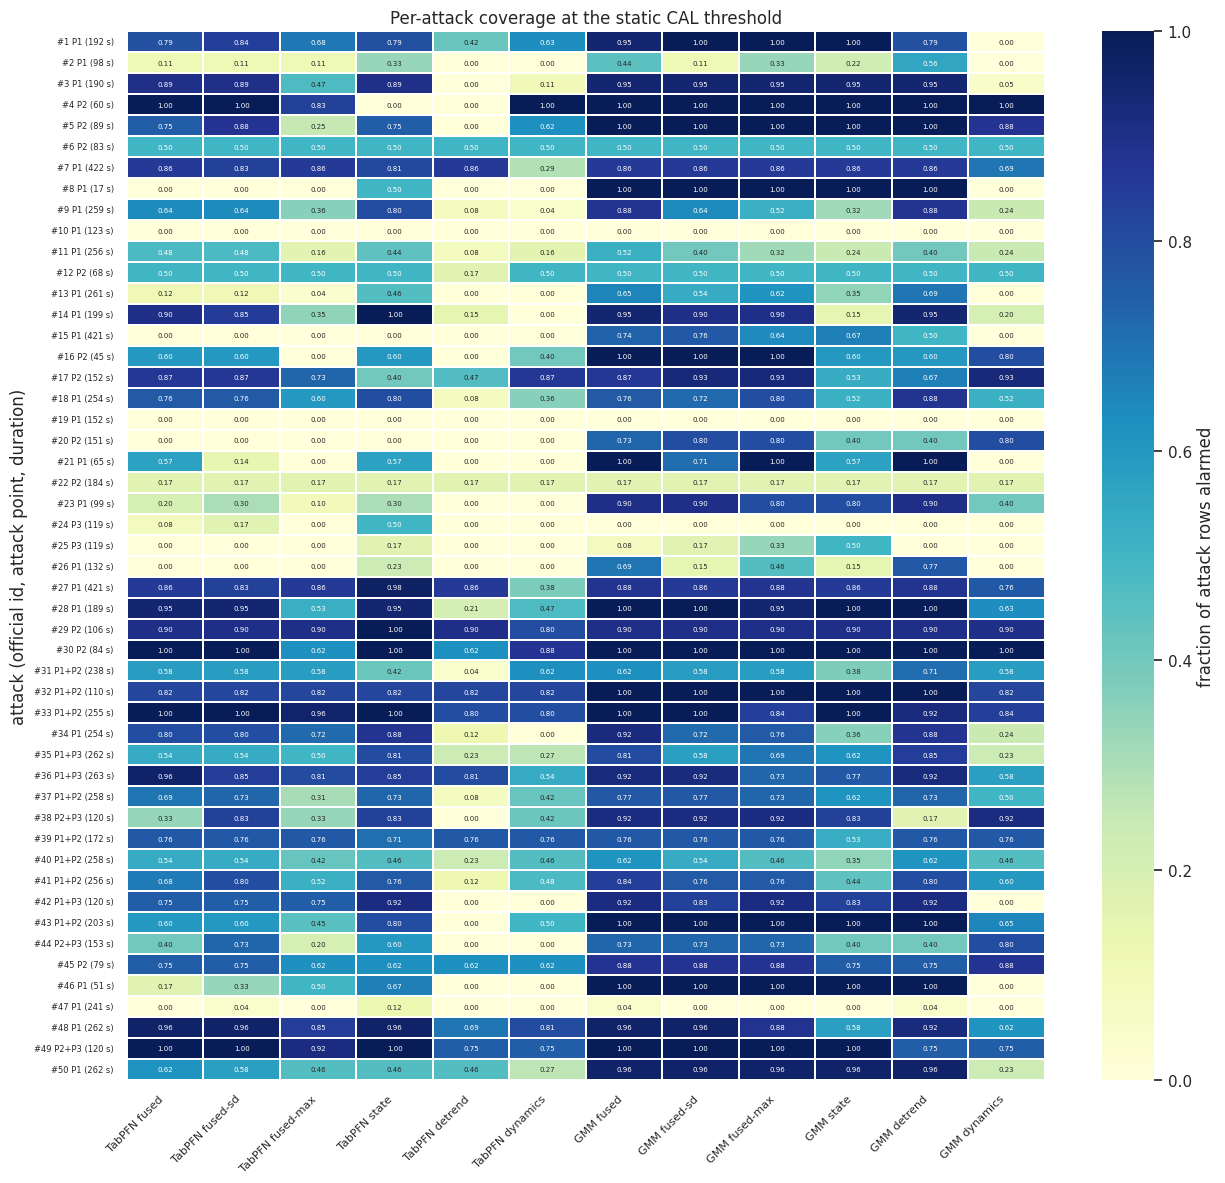

In [23]:
event_view = per_event_tables[(names[0], "static")][["segment", "attack_id", "attack_point", "start", "duration_s"]].copy()
for m in names:
    event_view[f"{m} detected"] = per_event_tables[(m, "static")]["detected"]
    event_view[f"{m} TTD (s)"] = per_event_tables[(m, "static")]["time_to_detect_s"]
event_view.to_csv(RUN_DIR / "results_per_attack.csv", index=False)

heat = pd.DataFrame({m: per_event_tables[(m, "static")]["fraction_alarmed"].to_numpy() for m in names})
heat.index = [f"#{r.attack_id} {r.attack_point} ({int(r.duration_s)} s)" for r in event_view.itertuples()]
fig, ax = plt.subplots(figsize=(0.75 * len(names) + 4, 0.2 * len(heat) + 2))
sns.heatmap(heat, annot=True, fmt=".2f", annot_kws={"size": 5}, cmap="YlGnBu", vmin=0, vmax=1, linewidths=0.3,
            cbar_kws={"label": "fraction of attack rows alarmed"}, ax=ax)
ax.set(xlabel="", ylabel="attack (official id, attack point, duration)", title="Per-attack coverage at the static CAL threshold")
ax.tick_params(axis="x", rotation=45, labelsize=8)
ax.tick_params(axis="y", labelsize=6)
plt.setp(ax.get_xticklabels(), ha="right")
plt.tight_layout()
save_fig(fig, "per_attack_coverage")
plt.show()

### **E5. Curves, score distributions and the score timeline (core methods)**

figure saved: output-figures/roc_pr_core_hai2103_v1.png


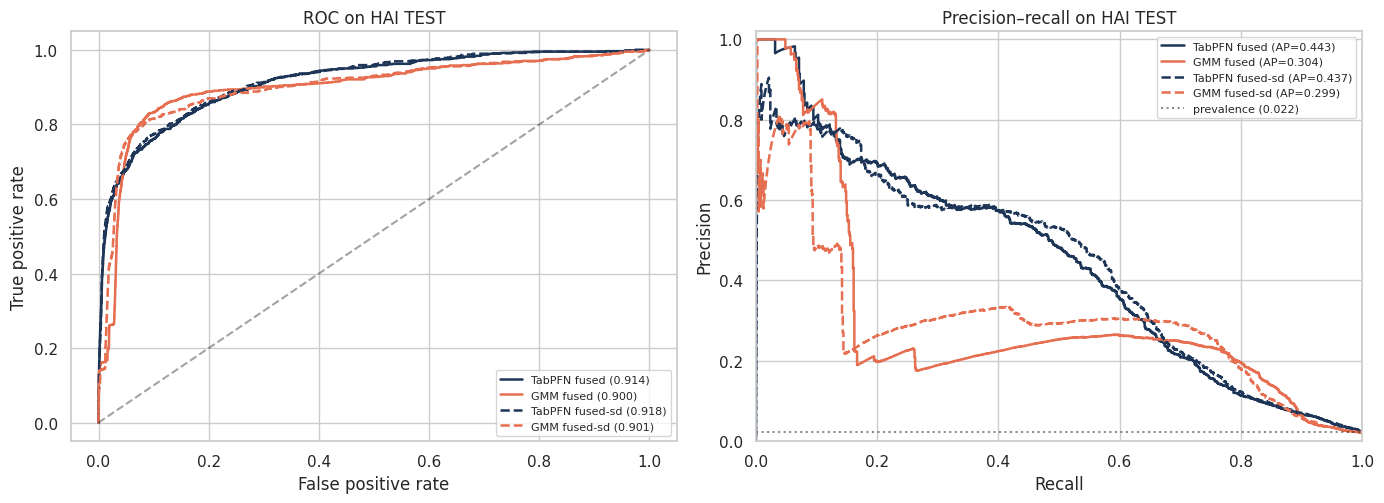

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for m in CORE:
    s = score_matrix[m]
    ls = "-" if m in PRIMARY.values() else "--"
    f, t_, _ = roc_curve(y_eval, s)
    axes[0].plot(f, t_, lw=1.8, ls=ls, color=family_color[m.split()[0]], label=f"{m} ({roc_auc_score(y_eval, s):.3f})")
    p, r, _ = precision_recall_curve(y_eval, s)
    axes[1].plot(r, p, lw=1.8, ls=ls, color=family_color[m.split()[0]], label=f"{m} (AP={average_precision_score(y_eval, s):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC on HAI TEST")
axes[1].axhline(y_eval.mean(), color="k", ls=":", alpha=0.5, label=f"prevalence ({y_eval.mean():.3f})")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–recall on HAI TEST", xlim=(0, 1), ylim=(0, 1.02))
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "roc_pr_core")
plt.show()

figure saved: output-figures/score_distributions_hai2103_v1.png


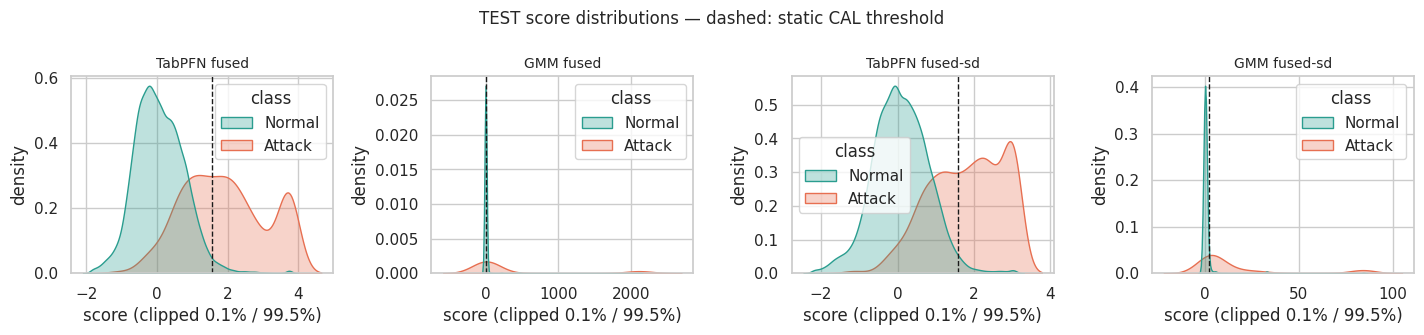

In [25]:
fig, axes = plt.subplots(1, len(CORE), figsize=(3.6 * len(CORE), 3.4), squeeze=False)
for ax, m in zip(axes[0], CORE):
    s = score_matrix[m]
    lo, hi = np.quantile(s, [0.001, 0.995])
    frame = pd.DataFrame({"score": np.clip(s, lo, hi), "class": np.where(y_eval == 1, "Attack", "Normal")})
    sns.kdeplot(data=frame, x="score", hue="class", hue_order=["Normal", "Attack"], common_norm=False,
                fill=True, alpha=0.3, palette={"Normal": "#2a9d8f", "Attack": "#e76f51"}, warn_singular=False, ax=ax)
    ax.axvline(THRESHOLDS[m], color="k", ls="--", lw=1)
    ax.set_title(m, fontsize=10)
    ax.set(xlabel="score (clipped 0.1% / 99.5%)", ylabel="density")
fig.suptitle("TEST score distributions — dashed: static CAL threshold", fontsize=12)
plt.tight_layout()
save_fig(fig, "score_distributions")
plt.show()

figure saved: output-figures/score_timeline_hai2103_v1.png


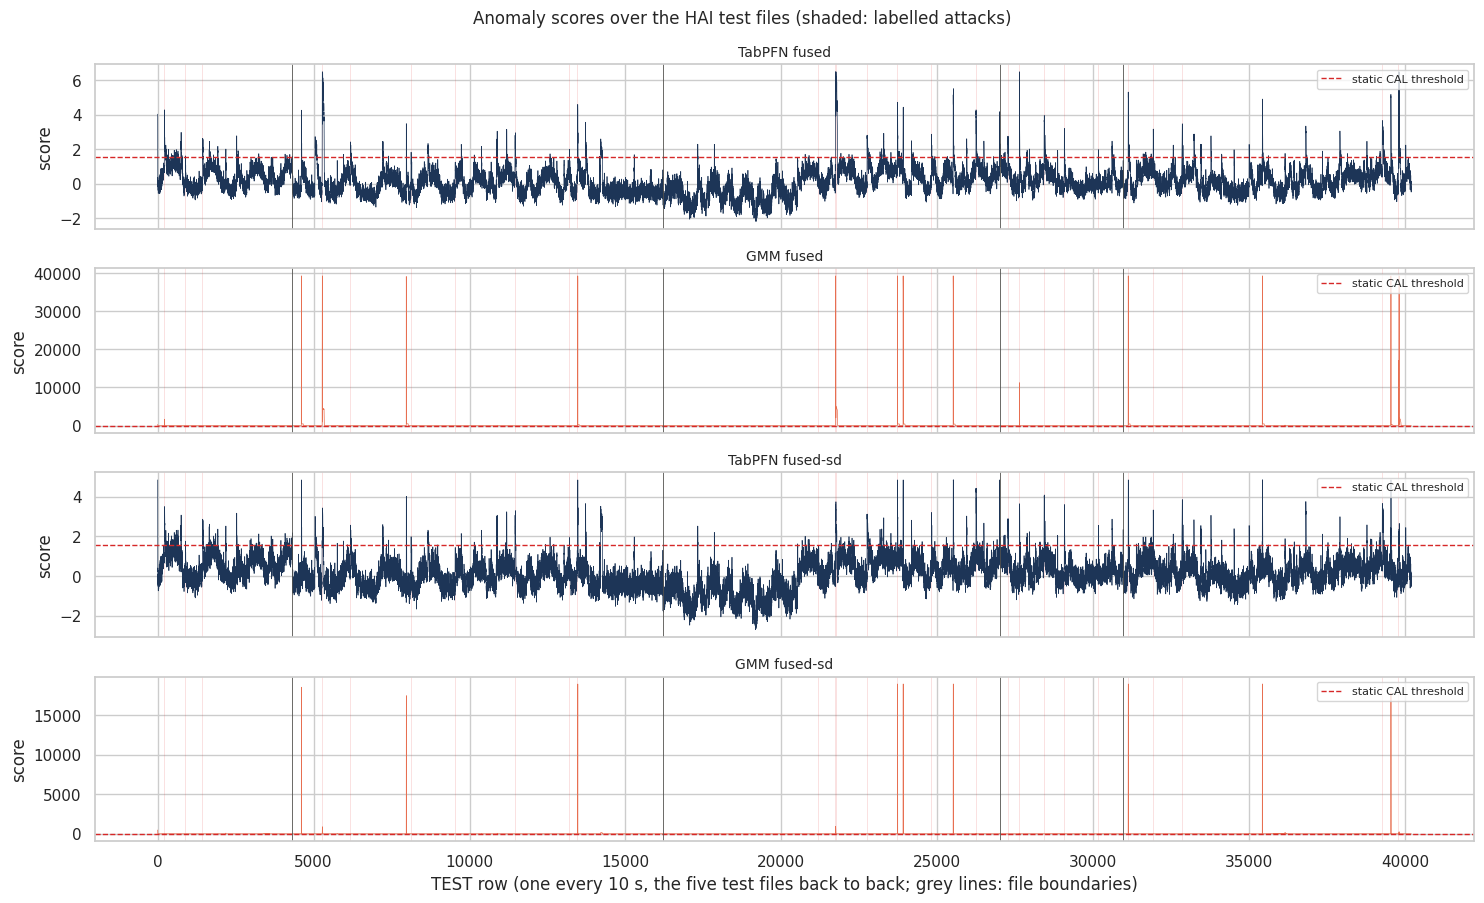

In [26]:
ts_index = pd.DatetimeIndex(ts_eval)
seg_rows = [(ts_index.searchsorted(s.start), ts_index.searchsorted(s.end, side="right")) for s in ev_segments.itertuples(index=False)]
file_breaks = np.flatnonzero(ts_index.to_series().diff().dt.total_seconds().to_numpy() != stride_s)[1:]   # TEST is five separate files
x = np.arange(len(ts_eval))
fig, axes = plt.subplots(len(CORE), 1, figsize=(15, 2.3 * len(CORE)), sharex=True, squeeze=False)
for ax, m in zip(axes[:, 0], CORE):
    s = score_matrix[m]
    ax.plot(x, np.clip(s, None, np.quantile(s, 0.999)), lw=0.5, color=family_color[m.split()[0]])
    ax.axhline(THRESHOLDS[m], color="#d62828", ls="--", lw=1, label="static CAL threshold")
    for a, b in seg_rows:
        ax.axvspan(a, b, color="#e34948", alpha=0.16, lw=0)
    for k in file_breaks:
        ax.axvline(k, color="#52514e", lw=0.6)
    ax.set_ylabel("score")
    ax.set_title(m, fontsize=10)
    ax.legend(loc="upper right", fontsize=8)
axes[-1, 0].set_xlabel("TEST row (one every 10 s, the five test files back to back; grey lines: file boundaries)")
fig.suptitle("Anomaly scores over the HAI test files (shaded: labelled attacks)", fontsize=12)
plt.tight_layout()
save_fig(fig, "score_timeline")
plt.show()

### **E6. False-alarm rate per test day: static vs. adaptive threshold**

figure saved: output-figures/daily_false_alarm_rate_hai2103_v1.png


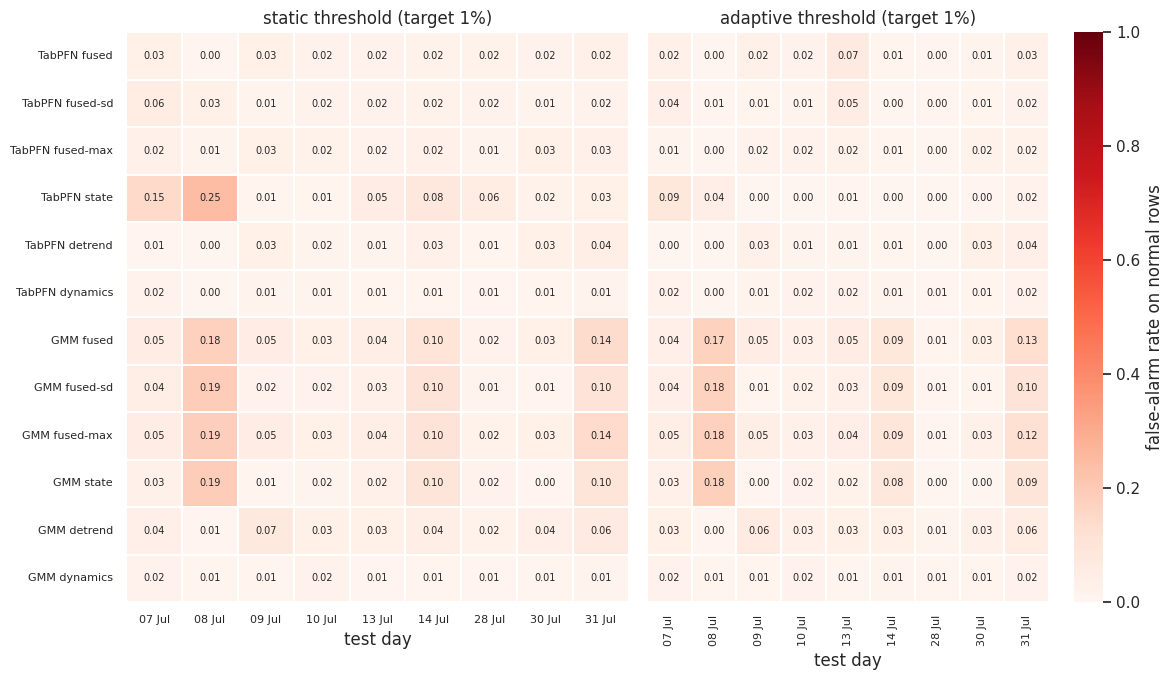

In [27]:
daily = {mode: pd.DataFrame({m: daily_false_alarm_rate(ts_eval, y_eval, s >= t) for m, (s, t) in src.items()}).T
         for mode, src in {"static": {m: (score_matrix[m], THRESHOLDS[m]) for m in names},
                           "adaptive": ADAPTIVE}.items()}
for mode, frame in daily.items():
    frame.columns = [pd.Timestamp(c).strftime("%d %b") for c in frame.columns]
    frame.to_csv(RUN_DIR / f"results_daily_false_alarm_rate_{mode}.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 0.38 * len(names) + 2.4), sharey=True)
for ax, (mode, frame) in zip(axes, daily.items()):
    sns.heatmap(frame.loc[names], annot=True, fmt=".2f", annot_kws={"size": 7}, cmap="Reds", vmin=0, vmax=1,
                linewidths=0.3, cbar=ax is axes[-1], cbar_kws={"label": "false-alarm rate on normal rows"}, ax=ax)
    ax.grid(False)
    ax.set(xlabel="test day", ylabel="", title=f"{mode} threshold (target {target_fpr:.0%})")
    ax.tick_params(labelsize=8)
plt.tight_layout()
save_fig(fig, "daily_false_alarm_rate")
plt.show()

### **E7. Rank agreement and cost**

figure saved: output-figures/spearman_rank_hai2103_v1.png


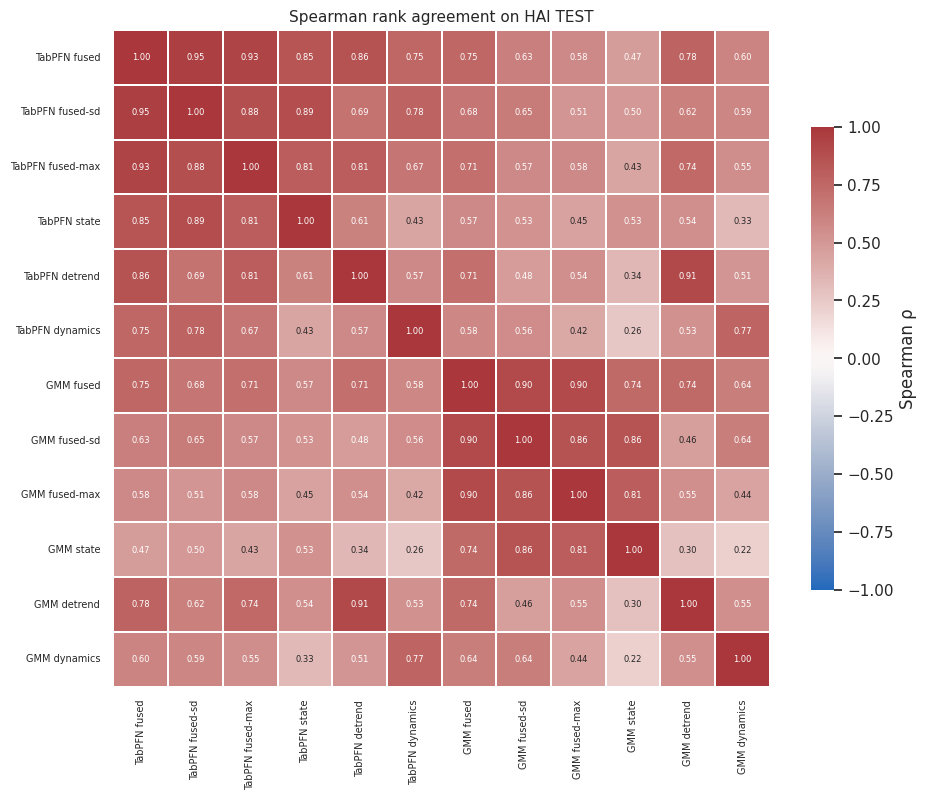

,model,ms_per_row
0,"TabPFN state (3 seeds, 48 features, GPU, batched)",91.9552
1,"TabPFN detrend (3 seeds, 47 features, GPU, bat...",88.8223
2,"TabPFN dynamics (3 seeds, 47 features, GPU, ba...",89.0151
3,"TabPFN fused (all views, GPU, batched)",269.7926
4,"GMM state (k=48, 48 features, CPU, batched)",0.0022
5,"GMM detrend (k=32, 47 features, CPU, batched)",0.0022
6,"GMM dynamics (k=32, 47 features, CPU, batched)",0.0015
7,"GMM fused (all views, CPU, batched)",0.0059


In [28]:
corr = pd.DataFrame(score_matrix).corr(method="spearman")
fig, ax = plt.subplots(figsize=(0.55 * len(names) + 3, 0.5 * len(names) + 2))
sns.heatmap(corr, annot=True, fmt=".2f", annot_kws={"size": 6}, cmap="vlag", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.3, cbar_kws={"shrink": 0.7, "label": "Spearman ρ"}, ax=ax)
ax.grid(False)
ax.tick_params(labelsize=7)
ax.set_title("Spearman rank agreement on HAI TEST", fontsize=11)
plt.tight_layout()
save_fig(fig, "spearman_rank")
plt.show()

teacher_cost = pd.read_csv(TEACHER_DIR / "teacher_cost.csv")
gmm_summary = pd.read_csv(RUN_DIR / "gmm_summary.csv")
cost_rows = [{"model": f"TabPFN {v} ({len(g)} seeds, {int(g['n_features'].iloc[0])} features, GPU, batched)",
              "ms_per_row": g["ms_per_row"].sum()} for v, g in teacher_cost.groupby("view", sort=False)]
cost_rows.append({"model": "TabPFN fused (all views, GPU, batched)", "ms_per_row": teacher_cost["ms_per_row"].sum()})
cost_rows += [{"model": f"GMM {r.view} (k={r.k}, {r.n_features} features, CPU, batched)", "ms_per_row": r.ms_per_row_batched}
              for r in gmm_summary.itertuples()]
cost_rows.append({"model": "GMM fused (all views, CPU, batched)", "ms_per_row": gmm_summary["ms_per_row_batched"].sum()})
cost = pd.DataFrame(cost_rows)
cost.to_csv(RUN_DIR / "results_cost.csv", index=False)
display(cost.round(4))

## **F. Final ROC/AUC evaluation: TabPFN teacher vs. GMM baseline**

This is the headline comparison, on the same TEST rows, labels and protocol, per fusion and per view. Metrics:
- **ROC-AUC** and **average precision**, with 95% CIs from the row-block and the event bootstraps.
- **pAUC** at FPR ≤ 10%, McClish-standardised (0.5 = random, 1 = perfect).
- **TPR at 1% FPR**: the ROC operating point. It uses labels, so it is an upper bound.
- The **deployable** operating point at the static and adaptive CAL thresholds: test FPR, recall and attacks detected.

In [29]:
res = main_results.set_index(["method", "threshold_mode"])
final_rows = []
for m in names:
    s = score_matrix[m]
    st, ad = res.loc[(m, "static")], res.loc[(m, "adaptive")]
    row = {"method": m, "family": m.split()[0], "group": m.split(" ", 1)[1], "roc_auc": roc_auc_score(y_eval, s)}
    for kind in boot:
        row[f"auc_{kind}_ci_low"], row[f"auc_{kind}_ci_high"] = np.quantile(boot[kind][f"auc|{m}"], [0.025, 0.975])
    row.update({
        "average_precision": average_precision_score(y_eval, s),
        f"pauc_fpr<={ecfg['pauc_max_fpr']}": roc_auc_score(y_eval, s, max_fpr=ecfg["pauc_max_fpr"]),
        "tpr@fpr=1% (oracle)": tpr_at_fpr(y_eval, s, 0.01),
        "static: test_fpr": st["test_fpr"], "static: recall": st["recall"], "static: attacks": int(st["attacks_detected"]),
        "adaptive: roc_auc": roc_auc_score(y_eval, np.nan_to_num(ADAPTIVE[m][0], nan=0.0)),
        "adaptive: test_fpr": ad["test_fpr"], "adaptive: recall": ad["recall"], "adaptive: attacks": int(ad["attacks_detected"]),
        "adaptive: composite_f1": ad["composite_f1"],
    })
    final_rows.append(row)
final_table = pd.DataFrame(final_rows).set_index("method")
final_table.to_csv(RUN_DIR / "results_final_roc_auc.csv")
display(final_table.round(4))

,family,group,roc_auc,auc_block_ci_low,auc_block_ci_high,auc_event_ci_low,auc_event_ci_high,average_precision,pauc_fpr<=0.1,tpr@fpr=1% (oracle),static: test_fpr,static: recall,static: attacks,adaptive: roc_auc,adaptive: test_fpr,adaptive: recall,adaptive: attacks,adaptive: composite_f1
method,,,,,,,,,,,,,,,,,,
TabPFN fused,TabPFN,fused,0.9143,0.8806,0.9447,0.8761,0.9454,0.4435,0.8098,0.4713,0.0209,0.5784,42,0.9019,0.0273,0.5254,41,0.4419
TabPFN fused-sd,TabPFN,fused-sd,0.9177,0.8850,0.9464,0.8809,0.9475,0.4375,0.8161,0.5017,0.0201,0.5908,43,0.9049,0.0217,0.4994,43,0.4887
TabPFN fused-max,TabPFN,fused-max,0.8952,0.8555,0.9306,0.8498,0.9322,0.3216,0.7664,0.2954,0.0228,0.4577,39,0.8838,0.0160,0.3529,34,0.4464
TabPFN state,TabPFN,state,0.8891,0.8470,0.9265,0.8406,0.9275,0.4698,0.7918,0.4724,0.0479,0.6212,45,0.8821,0.0131,0.4070,41,0.5485
TabPFN detrend,TabPFN,detrend,0.8763,0.8351,0.9119,0.8309,0.9127,0.2644,0.7301,0.2108,0.0211,0.2818,28,0.8701,0.0174,0.2424,22,0.3099
TabPFN dynamics,TabPFN,dynamics,0.8888,0.8606,0.9165,0.8553,0.9179,0.2425,0.7598,0.2954,0.0113,0.3224,32,0.8833,0.0139,0.3517,33,0.4682
GMM fused,GMM,fused,0.8997,0.8603,0.9367,0.8539,0.9353,0.3036,0.7777,0.1623,0.0562,0.7542,47,0.9012,0.0525,0.7170,46,0.3750
GMM fused-sd,GMM,fused-sd,0.9011,0.8643,0.9352,0.8565,0.9362,0.2991,0.8017,0.1443,0.0396,0.7091,46,0.9027,0.0363,0.6460,46,0.4368
GMM fused-max,GMM,fused-max,0.8864,0.8472,0.9259,0.8372,0.9250,0.2812,0.7523,0.1590,0.0574,0.7024,46,0.8851,0.0495,0.6212,46,0.3561


figure saved: output-figures/roc_final_hai2103_v1.png


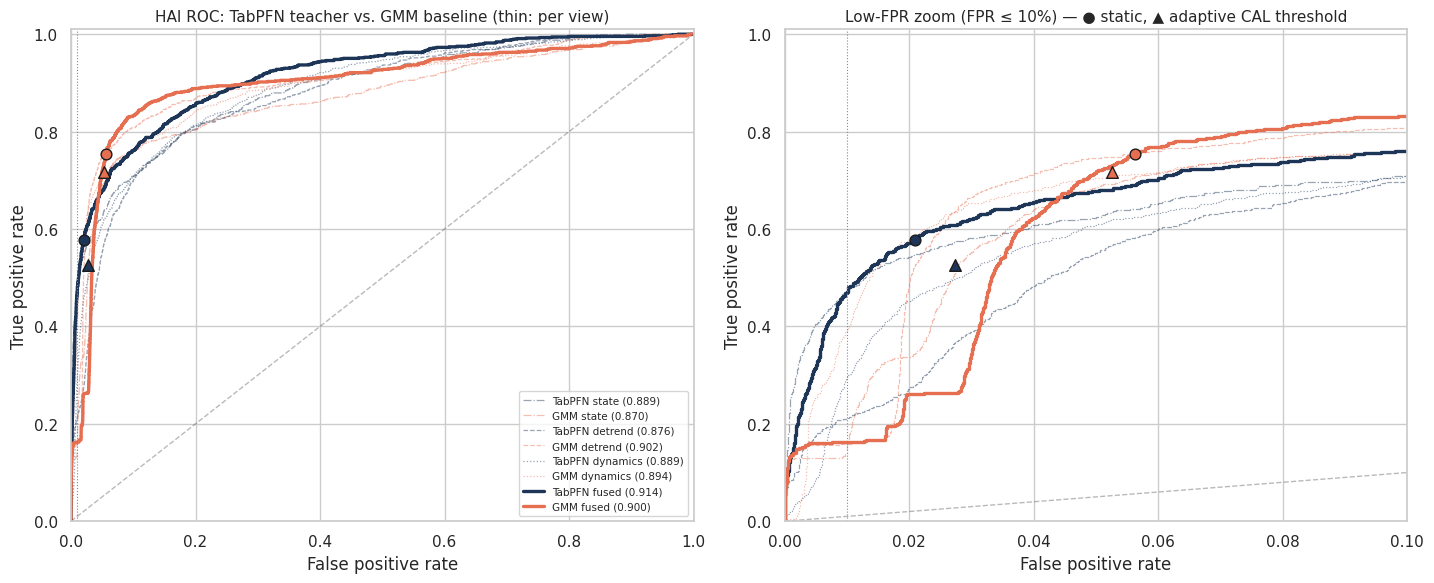

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 6))
view_ls = {"state": "-.", "detrend": "--", "dynamics": ":"}
for ax, xmax in zip(axes, [1.0, 0.10]):
    for v in view_names:
        for fam in ["TabPFN", "GMM"]:
            m = f"{fam} {v}"
            f, t_, _ = roc_curve(y_eval, score_matrix[m])
            ax.plot(f, t_, lw=0.9, ls=view_ls.get(v, "-"), color=family_color[fam], alpha=0.45,
                    label=f"{m} ({roc_auc_score(y_eval, score_matrix[m]):.3f})" if xmax == 1.0 else None)
    for fam, m in PRIMARY.items():
        f, t_, _ = roc_curve(y_eval, score_matrix[m])
        ax.plot(f, t_, lw=2.4, color=family_color[fam], label=f"{m} ({roc_auc_score(y_eval, score_matrix[m]):.3f})")
        for mode, marker, size in [("static", "o", 60), ("adaptive", "^", 70)]:
            r = res.loc[(m, mode)]
            ax.scatter([r["test_fpr"]], [r["recall"]], color=family_color[fam], s=size, marker=marker, edgecolor="k", zorder=5)
    ax.plot([0, 1], [0, 1], "k--", alpha=0.3, lw=1)
    ax.axvline(target_fpr, color="#888", lw=0.8, ls=":")
    ax.set(xlim=(0, xmax), ylim=(0, 1.01), xlabel="False positive rate", ylabel="True positive rate")
axes[0].set_title("HAI ROC: TabPFN teacher vs. GMM baseline (thin: per view)", fontsize=11)
axes[1].set_title("Low-FPR zoom (FPR ≤ 10%) — ● static, ▲ adaptive CAL threshold", fontsize=11)
axes[0].legend(fontsize=7.5, loc="lower right")
plt.tight_layout()
save_fig(fig, "roc_final")
plt.show()

### **F2. Paired AUC differences: TabPFN − GMM**

Δ = AUC(TabPFN x) − AUC(GMM x), computed on the same bootstrap replicates, with a 95% CI from each bootstrap. A difference is supported only if the **event** CI excludes 0.

,comparison,delta_auc,block_ci_low,block_ci_high,block_ci_excludes_0,event_ci_low,event_ci_high,event_ci_excludes_0
0,TabPFN fused − GMM fused,0.0146,-0.0078,0.0375,False,-0.0094,0.0404,False
1,TabPFN fused-sd − GMM fused-sd,0.0166,-0.0100,0.0415,False,-0.0101,0.0452,False
2,TabPFN fused-max − GMM fused-max,0.0088,-0.0218,0.0394,False,-0.0227,0.0396,False
3,TabPFN state − GMM state,0.0194,-0.0124,0.0488,False,-0.0146,0.0524,False
4,TabPFN detrend − GMM detrend,-0.0262,-0.0434,-0.0087,True,-0.0457,-0.0088,True
5,TabPFN dynamics − GMM dynamics,-0.0050,-0.0251,0.0178,False,-0.0270,0.0193,False
6,TabPFN fused-sd − TabPFN fused,0.0034,-0.0029,0.0099,False,-0.0029,0.0111,False
7,GMM fused-sd − GMM fused,0.0014,-0.0090,0.0119,False,-0.0093,0.0122,False
8,TabPFN fused − TabPFN state,0.0252,0.0081,0.0436,True,0.0080,0.0456,True
9,TabPFN fused − TabPFN detrend,0.0380,0.0228,0.0546,True,0.0225,0.0576,True


figure saved: output-figures/auc_differences_final_hai2103_v1.png


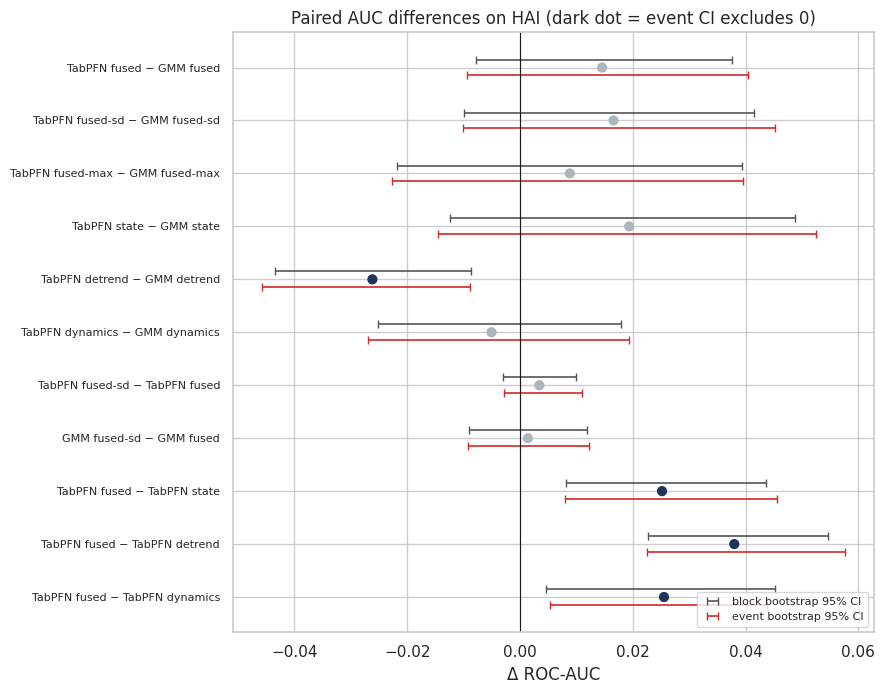

In [31]:
pairs = [(f"TabPFN {g}", f"GMM {g}") for g in GROUPS]
pairs += [(f"{fam} fused-sd", f"{fam} {ecfg['primary']}") for fam in ["TabPFN", "GMM"]]
pairs += [(f"TabPFN {ecfg['primary']}", f"TabPFN {v}") for v in view_names]
pairs = [(a, b) for a, b in pairs if a in names and b in names and a != b]

diff_rows = []
for a, b in pairs:
    row = {"comparison": f"{a} − {b}", "delta_auc": roc_auc_score(y_eval, score_matrix[a]) - roc_auc_score(y_eval, score_matrix[b])}
    for kind in boot:
        d = boot[kind][f"auc|{a}"] - boot[kind][f"auc|{b}"]
        row[f"{kind}_ci_low"], row[f"{kind}_ci_high"] = np.quantile(d, [0.025, 0.975])
        row[f"{kind}_ci_excludes_0"] = not (row[f"{kind}_ci_low"] <= 0 <= row[f"{kind}_ci_high"])
    diff_rows.append(row)
final_diffs = pd.DataFrame(diff_rows)
final_diffs.to_csv(RUN_DIR / "results_final_auc_differences.csv", index=False)
display(final_diffs.round(4))

fig, ax = plt.subplots(figsize=(9, 0.5 * len(final_diffs) + 1.6))
ypos = np.arange(len(final_diffs))
for off, kind, color in [(-0.15, "block", "#555"), (0.15, "event", "#d62828")]:
    ax.errorbar(final_diffs["delta_auc"], ypos + off, xerr=[final_diffs["delta_auc"] - final_diffs[f"{kind}_ci_low"],
                final_diffs[f"{kind}_ci_high"] - final_diffs["delta_auc"]], fmt="none", ecolor=color, capsize=3, lw=1.2,
                label=f"{kind} bootstrap 95% CI")
ax.scatter(final_diffs["delta_auc"], ypos, c=np.where(final_diffs["event_ci_excludes_0"], "#1d3557", "#adb5bd"), s=40, zorder=3)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(ypos)
ax.set_yticklabels(final_diffs["comparison"], fontsize=8)
ax.invert_yaxis()
ax.set(xlabel="Δ ROC-AUC", title="Paired AUC differences on HAI (dark dot = event CI excludes 0)")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
save_fig(fig, "auc_differences_final")
plt.show()

figure saved: output-figures/auc_tabpfn_vs_gmm_hai2103_v1.png


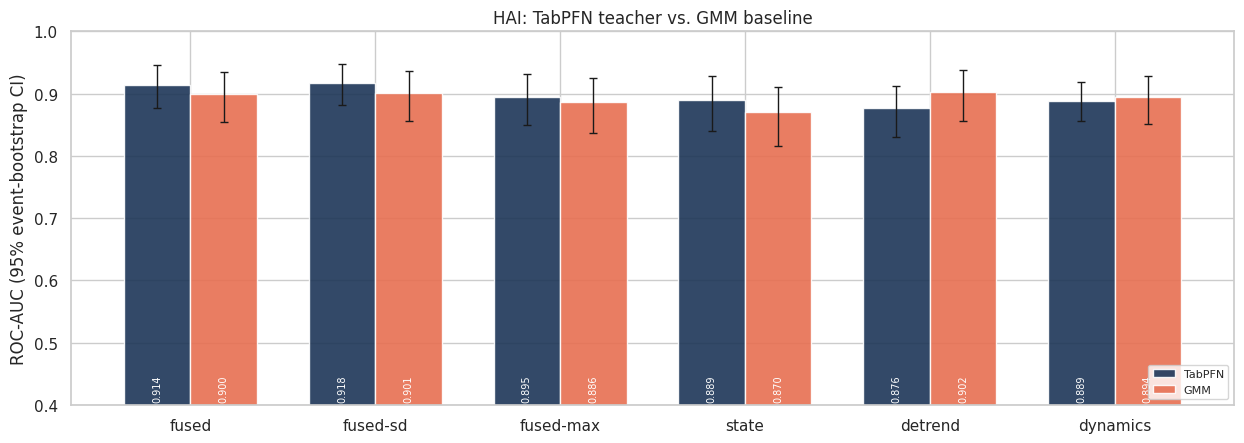

In [32]:
# TabPFN vs. GMM per fusion and per view: AUC with event-bootstrap CIs.
fig, ax = plt.subplots(figsize=(1.6 * len(GROUPS) + 3, 4.6))
width = 0.36
for j, fam in enumerate(["TabPFN", "GMM"]):
    est = np.array([final_table.loc[f"{fam} {g}", "roc_auc"] for g in GROUPS])
    lo = np.array([final_table.loc[f"{fam} {g}", "auc_event_ci_low"] for g in GROUPS])
    hi = np.array([final_table.loc[f"{fam} {g}", "auc_event_ci_high"] for g in GROUPS])
    x = np.arange(len(GROUPS)) + (j - 0.5) * width
    ax.bar(x, est, width, color=family_color[fam], label=fam, alpha=0.9)
    ax.errorbar(x, est, yerr=[est - lo, hi - est], fmt="none", ecolor="k", capsize=3, lw=1)
    for xi, e in zip(x, est):
        ax.text(xi, 0.405, f"{e:.3f}", ha="center", va="bottom", fontsize=7, color="white", rotation=90)
ax.set_xticks(np.arange(len(GROUPS)))
ax.set_xticklabels(GROUPS)
ax.set(ylim=(0.4, 1.0), ylabel="ROC-AUC (95% event-bootstrap CI)", title="HAI: TabPFN teacher vs. GMM baseline")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
save_fig(fig, "auc_tabpfn_vs_gmm")
plt.show()

### **F3. Cross-dataset view: SWaT v3 vs. HAI 21.03 v1**

This puts the same comparison (TabPFN − GMM, per fusion and per view) side by side for the two plants. Unlike WADI A1/A2, HAI is a different plant, so this is independent evidence. The SWaT numbers are read from `results/SWaT_A1A2-full-pipeline-v3/` (block-bootstrap CIs; SWaT has no `fused-sd`). It is skipped if that run is not on disk. The WADI A1 teacher run (`WADi_A1_2017_full_pipeline_v1`) can be compared in the same way with `results_final_*` files.

,dataset,group,TabPFN AUC,GMM AUC,ΔAUC,ci_low,ci_high,ci
0,SWaT 2015 (v3),fused,0.9124,0.9318,-0.0194,-0.0453,0.0005,row-block
1,HAI 21.03 (v1),fused,0.9143,0.8997,0.0146,-0.0094,0.0404,event
2,SWaT 2015 (v3),state,0.7981,0.9246,-0.1265,-0.2088,-0.0676,row-block
3,HAI 21.03 (v1),state,0.8891,0.8698,0.0194,-0.0146,0.0524,event
4,SWaT 2015 (v3),detrend,0.7347,0.8693,-0.1347,-0.1728,-0.0885,row-block
5,HAI 21.03 (v1),detrend,0.8763,0.9025,-0.0262,-0.0457,-0.0088,event
6,SWaT 2015 (v3),dynamics,0.8955,0.9049,-0.0094,-0.0299,0.0065,row-block
7,HAI 21.03 (v1),dynamics,0.8888,0.8938,-0.0050,-0.0270,0.0193,event


figure saved: output-figures/cross_dataset_tabpfn_vs_gmm_hai2103_v1.png


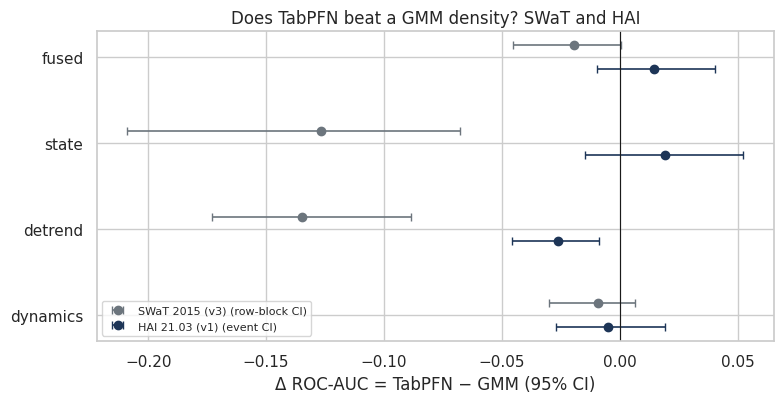

In [33]:
swat_final = SWAT_REFERENCE_DIR / "results_final_roc_auc.csv"
swat_diffs = SWAT_REFERENCE_DIR / "results_final_auc_differences.csv"
if swat_final.exists() and swat_diffs.exists():
    s_final = pd.read_csv(swat_final).set_index("method")
    s_diff = pd.read_csv(swat_diffs).set_index("comparison")
    cross_rows = []
    for g in ["fused"] + view_names:
        swat_key = f"TabPFN {g} − GMM {g}"
        if f"TabPFN {g}" in s_final.index and swat_key in s_diff.index:
            cross_rows.append({"dataset": "SWaT 2015 (v3)", "group": g,
                               "TabPFN AUC": s_final.loc[f"TabPFN {g}", "roc_auc"], "GMM AUC": s_final.loc[f"GMM {g}", "roc_auc"],
                               "ΔAUC": s_diff.loc[swat_key, "delta_auc"],
                               "ci_low": s_diff.loc[swat_key, "ci_low"], "ci_high": s_diff.loc[swat_key, "ci_high"],
                               "ci": "row-block"})
        d = final_diffs.set_index("comparison").loc[swat_key]
        cross_rows.append({"dataset": "HAI 21.03 (v1)", "group": g,
                           "TabPFN AUC": final_table.loc[f"TabPFN {g}", "roc_auc"], "GMM AUC": final_table.loc[f"GMM {g}", "roc_auc"],
                           "ΔAUC": d["delta_auc"], "ci_low": d["event_ci_low"], "ci_high": d["event_ci_high"], "ci": "event"})
    cross = pd.DataFrame(cross_rows)
    cross.to_csv(RUN_DIR / "results_cross_dataset_tabpfn_vs_gmm.csv", index=False)
    display(cross.round(4))

    groups_c = list(dict.fromkeys(cross["group"]))
    fig, ax = plt.subplots(figsize=(8, 0.6 * len(groups_c) + 1.8))
    for off, (ds, color) in zip([-0.14, 0.14], [("SWaT 2015 (v3)", "#6c757d"), ("HAI 21.03 (v1)", "#1d3557")]):
        sub = cross[cross["dataset"] == ds].set_index("group").reindex(groups_c)
        ypos = np.arange(len(groups_c)) + off
        ax.errorbar(sub["ΔAUC"], ypos, xerr=[sub["ΔAUC"] - sub["ci_low"], sub["ci_high"] - sub["ΔAUC"]],
                    fmt="o", color=color, ecolor=color, capsize=3, lw=1.2, label=f"{ds} ({sub['ci'].dropna().iloc[0]} CI)")
    ax.axvline(0, color="k", lw=0.8)
    ax.set_yticks(np.arange(len(groups_c)))
    ax.set_yticklabels(groups_c)
    ax.invert_yaxis()
    ax.set(xlabel="Δ ROC-AUC = TabPFN − GMM (95% CI)", title="Does TabPFN beat a GMM density? SWaT and HAI")
    ax.legend(fontsize=8, loc="lower left")
    plt.tight_layout()
    save_fig(fig, "cross_dataset_tabpfn_vs_gmm")
    plt.show()
else:
    print(f"SWaT v3 results not found in {SWAT_REFERENCE_DIR}; cross-dataset comparison skipped.")

### **F4. How to read the final evaluation**

1. **Does TabPFN beat the GMM on HAI?** Look at `TabPFN fused − GMM fused` (event CI, 50 attacks) and the per-view rows. On SWaT and WADI the result was a tie (−0.02 to 0.00 ROC-AUC). If HAI ties as well, the paper reports TabPFN as matching a classical density at about 10⁴× the cost.
2. **Does dynamics carry detection again?** Compare the `dynamics` rows with the fusions, and `fused-sd` with `fused`.
3. **Does the threshold hold?** Compare the ● static and ▲ adaptive markers with the daily false-alarm heatmap (E6): CAL (Aug) and TEST (July) are different recordings.
4. **Are the intervals tighter?** With 50 events, the event CIs should be clearly narrower than WADI's (±0.1–0.2). If they are not, the attacks are strongly clustered.

## **G. Results and figures manifest**

In [34]:
manifest = pd.DataFrame(
    [{"file": p.relative_to(RUN_DIR).as_posix(), "MB": round(p.stat().st_size / 1e6, 3)}
     for p in sorted(RUN_DIR.rglob("*")) if p.is_file()]
    + [{"file": p.as_posix(), "MB": round(p.stat().st_size / 1e6, 3)}
       for p in sorted(FIG_DIR.glob(f"*_{FIG_VERSION}.png"))]
)
display(manifest)
print(f"Run directory: {RUN_DIR.resolve()} | run {RUN_FINGERPRINT} | teacher {TEACHER_FINGERPRINT}")
print(f"Figures: {FIG_DIR.resolve()} ({len(list(FIG_DIR.glob(f'*_{FIG_VERSION}.png')))} files, {FIG_DPI} dpi)")

,file,MB
0,bootstrap_replicates_block.parquet,0.238
1,bootstrap_replicates_event.parquet,0.238
2,config.json,0.002
3,diagnostic_unseen_actuator_states.csv,0.000
4,drift_per_feature.csv,0.011
...,...,...
56,output-figures/score_distributions_hai2103_v1.png,0.620
57,output-figures/score_timeline_hai2103_v1.png,1.523
58,output-figures/spearman_rank_hai2103_v1.png,0.863
59,output-figures/split_and_views_hai2103_v1.png,2.749


Run directory: /home/jaume/_DEVELOPMENT/_projects/tabular-IDS/results/HAI_full_pipeline_v1 | run 7fbfd28556 | teacher 3998d76cb7
Figures: /home/jaume/_DEVELOPMENT/_projects/tabular-IDS/output-figures (14 files, 600 dpi)


## **Conclusions and next steps**

*Run `HAI_full_pipeline_v1`: run fingerprint 7fbfd28556, teacher fingerprint 3998d76cb7. Split: FIT 599,762 rows (1 Hz), CAL 25,345 (10 s), TEST 40,201 (10 s), 50 attack events, 887 attack rows.*

**1. TabPFN vs GMM (event bootstrap, 50 events).**

| view | TabPFN AUC | GMM AUC | Δ | 95% CI | supported |
|---|---|---|---|---|---|
| fused | 0.914 | 0.900 | +0.015 | [−0.009, +0.040] | no |
| state | 0.889 | 0.870 | +0.019 | [−0.015, +0.052] | no |
| detrend | 0.876 | 0.902 | −0.026 | [−0.046, −0.009] | **GMM better** |
| dynamics | 0.889 | 0.894 | −0.005 | [−0.027, +0.019] | no |

On HAI TabPFN ties GMM. On SWaT v3 GMM was better on state (−0.127) and detrend (−0.135) with CIs excluding 0; HAI is the first data set where the gap closes, but it never reverses.

**2. Operating point.** Static CAL 1% threshold: TabPFN fused 2.1% test FPR, 58% recall, 42/50 attacks; GMM fused 5.6%, 75%, 47/50. TPR at 1% FPR (oracle): TabPFN 0.471 vs GMM 0.162. TabPFN is the sharper detector at the strict end (AP 0.443 vs 0.304), GMM is better at moderate FPR (more attacks found). Adaptive thresholds do not improve either (TabPFN 2.7%, GMM 5.3%).

**3. Seeds and views.** Teacher AUC varies by at most 0.02 across the three seeds in each view (state 0.881–0.887, detrend 0.872–0.880, dynamics 0.876–0.895). Fusing views helps (0.914 vs 0.876–0.889 for single views); `fused-sd` is marginally best (0.918, 43/50 attacks) but the difference to `fused` is inside the CI.

**4. Calibration drift.** CAL (Aug) and TEST (Jul) are different recordings. The KS distance between FIT and TEST-normal exceeds 0.2 for several state features, and the test FPR overshoots the 1% target by about 2×. Treat every static-threshold figure as indicative; the ranking metrics (AUC, pAUC, TPR@1%) are not affected.

**5. Next steps.** (a) The untrained baselines (see `HAI_baselines_v1`) match TabPFN on pAUC, so TabPFN's lack of an edge is the main finding to carry into the paper. (b) Attacks 10 and 19 (P1) are missed by every method: inspect them. (c) Replicate on HAI 22.04 if the cross-dataset claim needs a fourth data set.
